# Single-Cell Isotope Incorporation Rates via Peak-Relative Projection
## *Synechocystis* sp. PCC 6803, $^{13}$C and $^{15}$N

For each cell, assign it to a peak (cluster), then:

1. **Standardize**: $k = (x - \mu_{t,j})/\sigma_{t,j}$ — this cell's z-score within its
   own assigned peak $j$'s distribution, at its own timepoint $t$.
2. **Project**: $x_{t-\Delta t} = \mu_{t-\Delta t,j} + k\,\sigma_{t-\Delta t,j}$ — using
   the *same* $k$ with peak $j$'s mean/std at the *previous* timepoint, giving a
   personalized (not just population-mean) reference value for that specific cell.
3. **Rate**: $r_{\mathrm{cell}} = \frac{1}{T}\log(x_t / x_{t-\Delta t})$ — a plain
   specific (log fold-change) incorporation rate. No asymptotic ceiling is used, unlike
   an earlier version of this analysis — that ceiling-normalized rate made carbon look
   faster than nitrogen purely because carbon's ceiling is ~8x smaller, not because it
   actually incorporates faster (see Section 8 below).

Segments: 0h→4h, 4h→12h, 12h→24h. No ion-counting uncertainty propagation (dropped per
request) — output files carry `[rate, peak_assignment]` only.


In [1]:
import pandas as pd
import numpy as np
import matplotlib
#matplotlib.use("Agg")  # remove/comment this line to render inline instead of only saving to file
import matplotlib.pyplot as plt
from scipy.stats import skew
from sklearn.mixture import GaussianMixture
from pathlib import Path

plt.rcParams.update({
    "font.size": 10.5,
    "figure.dpi": 150,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
rng = np.random.default_rng(0)


## 1. Data loading

In [4]:
DATA_DIR = Path("experiments/new_data/replicates/")

FILES = {
    ("0h", "blank"): "blank.ods",
    ("4h", "rep1"): "4h_rep1.ods",
    ("4h", "rep2"): "4h_rep2.ods",
    ("12h", "rep1"): "12h_rep1.ods",
    ("12h", "rep2"): "12h_rep2.ods",
    ("24h", "rep1"): "24h_rep1.ods",
    ("24h", "rep2"): "24h_rep2.ods",
    ("4h", "rep2_filt"): "4h_rep2_filtered.csv",
    ("12h", "rep2_filt"): "12h_rep2_filtered.csv",
    ("24h", "rep2_filt"): "24h_rep2_filtered.csv",
    ("4h", "rep1_filt"): "4h_rep1_filtered.csv",
    ("12h", "rep1_filt"): "12h_rep1_filtered.csv",
    ("24h", "rep1_filt"): "24h_rep1_filtered.csv",
}

def load(key):
    if 'ods' in FILES[key]:
        return pd.read_excel(DATA_DIR / FILES[key], sheet_name="Sheet1", engine="odf")
    elif 'csv' in FILES[key]:
        return pd.read_csv(DATA_DIR / FILES[key])
    else:
        return

timepoints = ["4h", "12h", "24h"]
T_clock = {"0h": 0.0, "4h": 4.0, "12h": 12.0, "24h": 24.0}

blank = load(("0h", "blank"))
t4_rep2 = load(("4h", "rep2"))
t12_rep2 = load(("12h", "rep2"))
t24_rep2 = load(("24h", "rep2"))

# thresholds from the blank distribution
c_thresh = blank["C_ratio"].mean() - blank["C_ratio"].std()
n_thresh = blank["N_ratio"].mean() - blank["N_ratio"].std()

def filter_below_blank(df, c_thresh, n_thresh):
    return df[(df["C_ratio"] >= c_thresh) & (df["N_ratio"] >= n_thresh)]

t4_rep2_filt = filter_below_blank(t4_rep2, c_thresh, n_thresh)
t12_rep2_filt = filter_below_blank(t12_rep2, c_thresh, n_thresh)
t24_rep2_filt = filter_below_blank(t24_rep2, c_thresh, n_thresh)

def save_filtered(df, timepoint, replicate):
    filename = f"experiments/new_data/replicates/{timepoint}_{replicate}_filtered.csv"
    df.to_csv(filename, index=False)
    print(f"Saved {filename} ({len(df)} rows)")

save_filtered(t4_rep2_filt, "4h", "rep2")
save_filtered(t12_rep2_filt, "12h", "rep2")
save_filtered(t24_rep2_filt, "24h", "rep2")

save_filtered(t4_rep2_filt, "4h", "rep1")
save_filtered(t12_rep2_filt, "12h", "rep1")
save_filtered(t24_rep2_filt, "24h", "rep1")

pooled = {tp: pd.concat([load((tp, "rep1")), load((tp, "rep2"))], ignore_index=True)
          for tp in timepoints}
pooled = {tp: pd.concat([load((tp, "rep1_filt"))], ignore_index=True)
          for tp in timepoints}
all_pooled = pd.concat([pooled[tp] for tp in timepoints], ignore_index=True)




Saved experiments/new_data/replicates/4h_rep2_filtered.csv (591 rows)
Saved experiments/new_data/replicates/12h_rep2_filtered.csv (520 rows)
Saved experiments/new_data/replicates/24h_rep2_filtered.csv (334 rows)
Saved experiments/new_data/replicates/4h_rep1_filtered.csv (591 rows)
Saved experiments/new_data/replicates/12h_rep1_filtered.csv (520 rows)
Saved experiments/new_data/replicates/24h_rep1_filtered.csv (334 rows)


Saved experiments/new_data/replicates/4h_rep2_filtered.csv (591 rows)
Saved experiments/new_data/replicates/12h_rep2_filtered.csv (520 rows)
Saved experiments/new_data/replicates/24h_rep2_filtered.csv (334 rows)


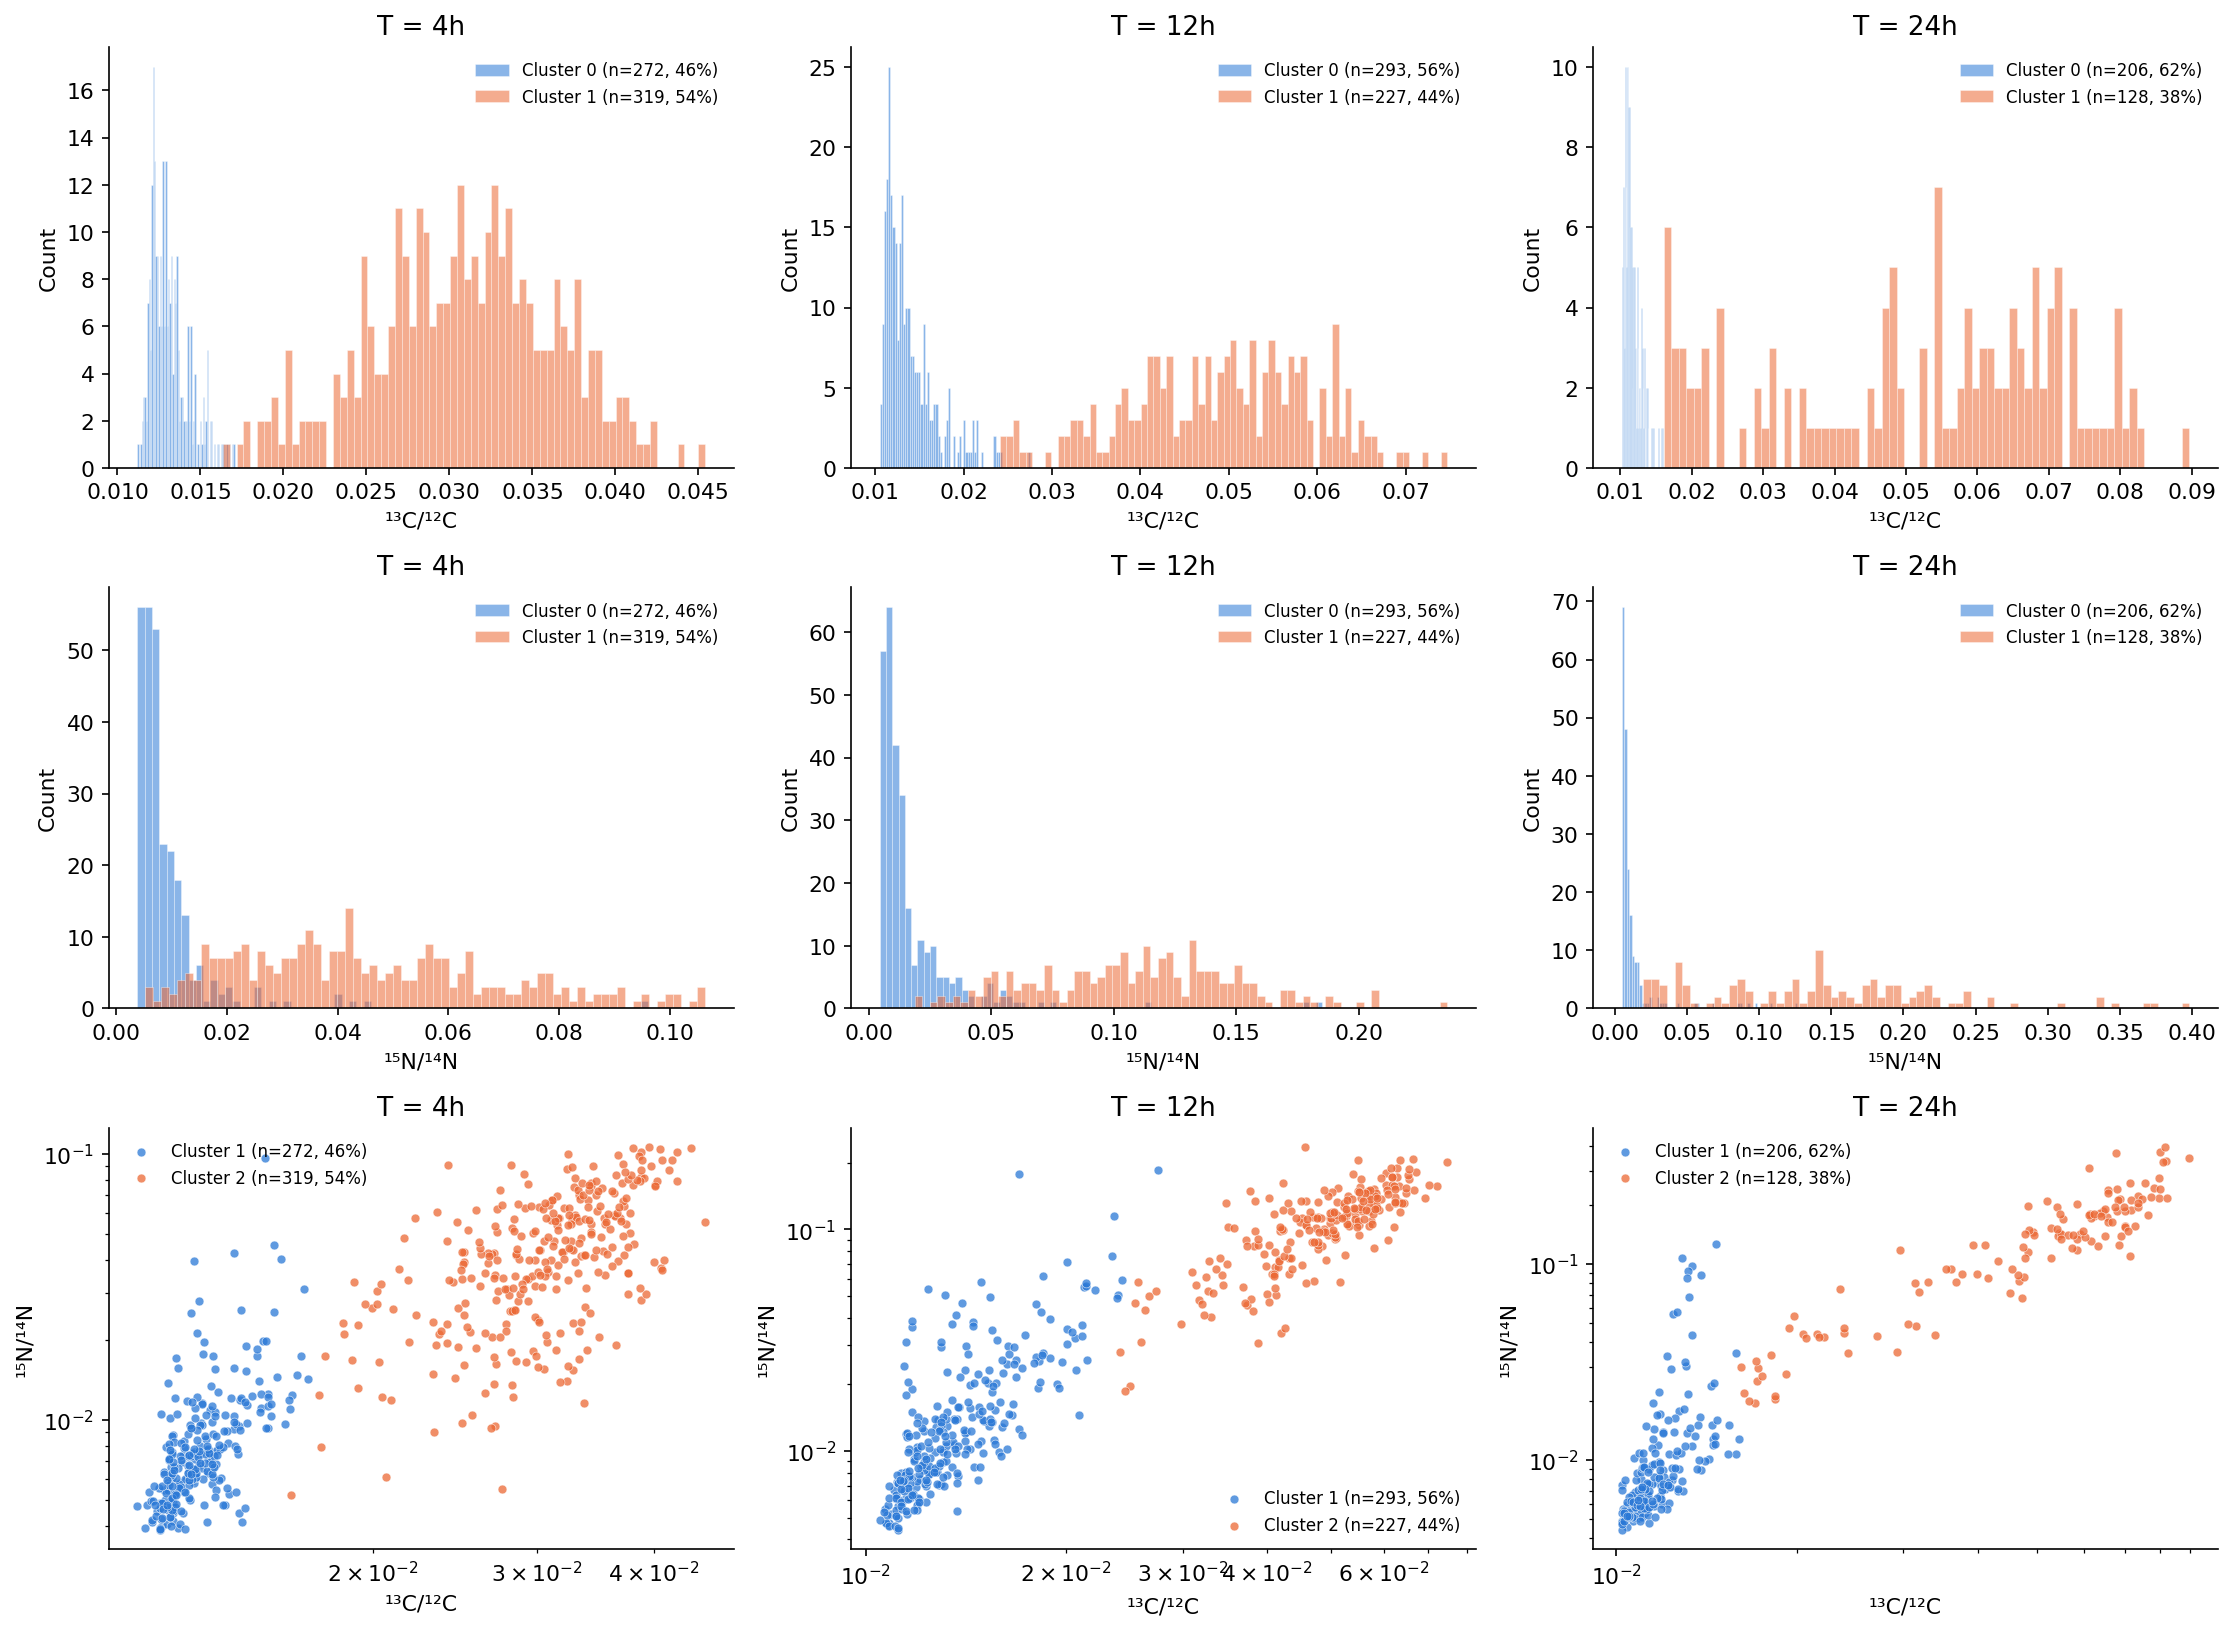

\begin{table}[h]
\centering
\footnotesize
\renewcommand{\arraystretch}{1.1}
\setlength{\tabcolsep}{6pt}
\caption{Cluster-wise and population-level C and N ratios by time point (mean $\pm$ SD). $n$ (\%) is the cluster size as a fraction of that timepoint's clustered population. Population columns pool both clusters together, i.e.\ the same raw distribution before the GMM split. At 0\,h no enrichment split was detected, so a single baseline value is reported.}
\label{tab:cluster-ratios}
\begin{tabular}{@{}l ccc ccc cc@{}}
\toprule
\multirow{2}{*}{\textbf{Time}} & \multicolumn{3}{c}{\textbf{Low cluster}} & \multicolumn{3}{c}{\textbf{High cluster}} & \multicolumn{2}{c}{\textbf{Population}} \\
\cmidrule(lr){2-4} \cmidrule(lr){5-7} \cmidrule(lr){8-9}
 & $n$ (\%) & C ratio & N ratio & $n$ (\%) & C ratio & N ratio & C ratio & N ratio \\
\midrule
0h & \multicolumn{8}{c}{C ratio $= 0.0104 \pm 0.0002$ \quad N ratio $= 0.0039 \pm 0.0001$ (baseline, no cluster split)} \\
\addlinespace
4h & 272 (46\

In [4]:
"""
Cluster log(C_ratio) vs log(N_ratio) into two groups for two timepoints, and
check that BOTH ratios come out bimodal under the split.

Figure layout (3 rows x 2 cols, one column per timepoint):
  row 0: scatter of log(C_ratio) vs log(N_ratio), colored by cluster
  row 1: overlaid histograms of log(C_ratio) for the two clusters
  row 2: overlaid histograms of log(N_ratio) for the two clusters

Why this changed from plain k-means:
  - C_ratio and N_ratio don't have the same spread (N_ratio's range is often
    ~2-3x C_ratio's). Plain k-means on the raw log values lets whichever
    variable has more variance dominate the Euclidean distance, so the split
    mostly tracks N_ratio and C_ratio ends up smeared across both clusters
    (poor separation in the C_ratio marginal -> not bimodal). Fix: z-score
    both log-ratios (StandardScaler) before clustering so they contribute
    equally.
  - K-means also assumes round, equal-size, equal-variance clusters. Your
    data is an elongated, positively-correlated cloud (a tight low group +
    a more spread-out high group) - not what k-means is built for. A
    Gaussian Mixture Model (GMM) fits ellipses aligned with the actual
    covariance of each group and is the standard tool when you expect the
    data to be a mixture of ~2 (bimodal) populations. GMM is now the
    default; k-means is kept as an option for comparison.

Requires: numpy, pandas, matplotlib, scikit-learn
    pip install scikit-learn matplotlib pandas numpy
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

# ---- categorical colors (colorblind-safe adjacent pair) ----
COLOR_CLUSTER0 = "#2a78d6"  # blue  = "low" group
COLOR_CLUSTER1 = "#eb6834"  # orange = "high" group
CLUSTER_COLORS = [COLOR_CLUSTER0, COLOR_CLUSTER1]


def cluster_log_ratios(df, method="gmm", n_clusters=2, random_state=42):
    """
    Compute log(C_ratio), log(N_ratio), standardize them, and split into
    n_clusters groups.

    method: "gmm" (default, recommended) or "kmeans".

    Clusters are relabeled so cluster 0 always has the lower mean
    (standardized logC + logN) -> "low" group, cluster 1 -> "high" group.
    This keeps colors/labels consistent across panels and datasets, since
    both GMM and k-means assign arbitrary label numbers each run.

    Returns (data, model, scaler) where data has columns
    [logC, logN, cluster].
    """
    logC = np.log(df["C_ratio"])
    logN = np.log(df["N_ratio"])

    data = pd.DataFrame({"logC": logC, "logN": logN})
    data = data.replace([np.inf, -np.inf], np.nan).dropna()
    data["C_ratio"] = df["C_ratio"]
    data["N_ratio"] = df["N_ratio"]

    scaler = StandardScaler()
    X = scaler.fit_transform(data[["logC", "logN"]])

    if method == "gmm":
        model = GaussianMixture(
            n_components=n_clusters, covariance_type="full",
            random_state=random_state, n_init=10,
        )
        labels = model.fit_predict(X)
    elif method == "kmeans":
        model = KMeans(n_clusters=n_clusters, random_state=random_state, n_init=10)
        labels = model.fit_predict(X)
    else:
        raise ValueError("method must be 'gmm' or 'kmeans'")

    # relabel by ascending mean score so 0 = low group, 1 = high group
    score = X.sum(axis=1)
    order = pd.Series(score, index=data.index).groupby(labels).mean().sort_values().index
    relabel = {old: new for new, old in enumerate(order)}
    data["cluster"] = [relabel[l] for l in labels]

    return data, model, scaler


def plot_scatter_log(ax, data, title):
    n_total = len(data)
    for cluster_id in sorted(data["cluster"].unique()):
        sub = data[data["cluster"] == cluster_id]
        pct = 100 * len(sub) / n_total
        ax.scatter(
            sub["logC"], sub["logN"],
            s=18, alpha=0.75,
            color=CLUSTER_COLORS[cluster_id],
            edgecolor="white", linewidth=0.3,
            label=f"Cluster {cluster_id} (n={len(sub)}, {pct:.0f}%)",
        )
    ax.set_xlabel("log(C_ratio)")
    ax.set_ylabel("log(N_ratio)")
    ax.set_title(title)
    ax.legend(frameon=False, fontsize=8)


def plot_scatter(ax, data, title):
    n_total = len(data)
    for cluster_id in sorted(data["cluster"].unique()):
        sub = data[data["cluster"] == cluster_id]
        pct = 100 * len(sub) / n_total
        ax.scatter(
            sub["C_ratio"], sub["N_ratio"],
            s=18, alpha=0.75,
            color=CLUSTER_COLORS[cluster_id],
            edgecolor="white", linewidth=0.3,
            label=f"Cluster {cluster_id+1} (n={len(sub)}, {pct:.0f}%)",
        )
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("¹³C/¹²C")
    ax.set_ylabel("¹⁵N/¹⁴N")
    ax.set_title(title)
    ax.legend(frameon=False, fontsize=8)


def plot_hist(ax, data, title, column, bins=70):
    n_total = len(data)
    for cluster_id in sorted(data["cluster"].unique()):
        sub = data[data["cluster"] == cluster_id]
        pct = 100 * len(sub) / n_total
        ax.hist(
            sub[column], bins=bins, alpha=0.55,
            color=CLUSTER_COLORS[cluster_id],
            edgecolor="white", linewidth=0.3,
            label=f"Cluster {cluster_id} (n={len(sub)}, {pct:.0f}%)",
        )
    xlabel = "¹³C/¹²C" if column == "C_ratio" else "¹⁵N/¹⁴N"
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Count")
    ax.set_title(title)
    ax.legend(frameon=False, fontsize=8)


def plot_hist_log(ax, data, title, column, bins=50):
    n_total = len(data)
    for cluster_id in sorted(data["cluster"].unique()):
        sub = data[data["cluster"] == cluster_id]
        pct = 100 * len(sub) / n_total
        ax.hist(
            sub[column], bins=bins, alpha=0.55,
            color=CLUSTER_COLORS[cluster_id],
            edgecolor="white", linewidth=0.3,
            label=f"Cluster {cluster_id} (n={len(sub)}, {pct:.0f}%)",
        )
    xlabel = "log(C_ratio)" if column == "logC" else "log(N_ratio)"
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Count")
    ax.set_title(title)
    ax.legend(frameon=False, fontsize=8)


def cluster_stats(df, method="gmm", random_state=42):
    """
    Cluster df into 2 groups (via cluster_log_ratios, in log-space) and
    return mean/std of the RAW C_ratio and N_ratio per cluster, plus the
    cluster's size (n) and fraction of the total clustered population.
    Keys are 0 ("low") and 1 ("high").
    """
    data, _, _ = cluster_log_ratios(df, method=method, random_state=random_state)
    n_total = len(data)
    stats = {}
    for cluster_id in (0, 1):
        sub = data[data["cluster"] == cluster_id]
        n = len(sub)
        stats[cluster_id] = {
            "C_mean": sub["C_ratio"].mean(), "C_std": sub["C_ratio"].std(),
            "N_mean": sub["N_ratio"].mean(), "N_std": sub["N_ratio"].std(),
            "n": n,
            "frac": n / n_total if n_total else float("nan"),
        }
    return stats


def population_stats(df):
    """Mean/std of raw C_ratio and N_ratio, ignoring cluster membership."""
    return {
        "C_mean": df["C_ratio"].mean(), "C_std": df["C_ratio"].std(),
        "N_mean": df["N_ratio"].mean(), "N_std": df["N_ratio"].std(),
    }


def fmt(mean, std, decimals=4):
    return f"${mean:.{decimals}f} \\pm {std:.{decimals}f}$"


def fmt_n(n, frac):
    return f"{n} ({100 * frac:.0f}\\%)"

def fmt(mean, std, mean_decimals=4, std_decimals=3):
    mean_str = f"{mean:.{mean_decimals}f}"
    std_str = f"{std:.{std_decimals}f}"
    # trim one trailing zero off std (0.020 -> 0.02) to shave a bit more width;
    # leaves things like 0.023 or 0.001 untouched since they don't end in "0"
    if std_str.endswith("0") and not std_str.endswith(".0"):
        std_str = std_str[:-1]
    return f"${mean_str} \\pm {std_str}$"


def fmt_n(n, frac):
    return f"{n} ({100 * frac:.0f}\\%)"


def build_latex_table(blank, timepoint_dfs, method="gmm", mean_decimals=4, std_decimals=3):
    """
    blank: 0h dataframe -> reported as a single baseline row, no clustering.
    timepoint_dfs: ordered list of (label, df) tuples, e.g.
        [("4h", t4_rep2_filt), ("12h", t12_rep2_filt), ("24h", t24_rep2_filt)]

    Columns: Time | Low(n, C, N) | High(n, C, N) | Population(C, N)
    """
    c0_mean, c0_std = blank["C_ratio"].mean(), blank["C_ratio"].std()
    n0_mean, n0_std = blank["N_ratio"].mean(), blank["N_ratio"].std()

    rows = [
        rf"0h & \multicolumn{{8}}{{c}}{{C ratio $= {c0_mean:.{mean_decimals}f} \pm {c0_std:.{mean_decimals}f}$"
        rf" \quad N ratio $= {n0_mean:.{mean_decimals}f} \pm {n0_std:.{mean_decimals}f}$ (baseline, no cluster split)}} \\",
        r"\addlinespace",
    ]

    for label, df in timepoint_dfs:
        stats = cluster_stats(df, method=method, random_state=42)
        low, high = stats[0], stats[1]
        pop = population_stats(df)
        rows.append(
            f"{label} & {fmt_n(low['n'], low['frac'])} & "
            f"{fmt(low['C_mean'], low['C_std'], mean_decimals, std_decimals)} & "
            f"{fmt(low['N_mean'], low['N_std'], mean_decimals, std_decimals)} & "
            f"{fmt_n(high['n'], high['frac'])} & "
            f"{fmt(high['C_mean'], high['C_std'], mean_decimals, std_decimals)} & "
            f"{fmt(high['N_mean'], high['N_std'], mean_decimals, std_decimals)} & "
            f"{fmt(pop['C_mean'], pop['C_std'], mean_decimals, std_decimals)} & "
            f"{fmt(pop['N_mean'], pop['N_std'], mean_decimals, std_decimals)} \\\\"
        )

    body = "\n".join(rows)

    return rf"""\begin{{table}}[h]
\centering
\footnotesize
\renewcommand{{\arraystretch}}{{1.1}}
\setlength{{\tabcolsep}}{{6pt}}
\caption{{Cluster-wise and population-level C and N ratios by time point (mean $\pm$ SD). $n$ (\%) is the cluster size as a fraction of that timepoint's clustered population. Population columns pool both clusters together, i.e.\ the same raw distribution before the GMM split. At 0\,h no enrichment split was detected, so a single baseline value is reported.}}
\label{{tab:cluster-ratios}}
\begin{{tabular}}{{@{{}}l ccc ccc cc@{{}}}}
\toprule
\multirow{{2}}{{*}}{{\textbf{{Time}}}} & \multicolumn{{3}}{{c}}{{\textbf{{Low cluster}}}} & \multicolumn{{3}}{{c}}{{\textbf{{High cluster}}}} & \multicolumn{{2}}{{c}}{{\textbf{{Population}}}} \\
\cmidrule(lr){{2-4}} \cmidrule(lr){{5-7}} \cmidrule(lr){{8-9}}
 & $n$ (\%) & C ratio & N ratio & $n$ (\%) & C ratio & N ratio & C ratio & N ratio \\
\midrule
{body}
\bottomrule
\end{{tabular}}
\end{{table}}
"""

def main(t4_rep2, t12_rep2, t24_rep2, method="gmm"):
    datasets = {"T = 4h": t4_rep2, "T = 12h": t12_rep2, "T = 24h": t24_rep2}

    fig, axes = plt.subplots(3, 3, figsize=(15, 11))

    for col_idx, (name, df) in enumerate(datasets.items()):
        data, model, scaler = cluster_log_ratios(df, method=method, n_clusters=2)

        plot_hist(axes[0, col_idx], data, f"{name}", column="C_ratio")
        plot_hist(axes[1, col_idx], data, f"{name}", column="N_ratio")
        plot_scatter(axes[2, col_idx], data, f"{name}")

    plt.tight_layout()
    plt.savefig("clusters_figure.png", dpi=200)
    plt.show()

    timepoint_dfs = [("4h", t4_rep2), ("12h", t12_rep2), ("24h", t24_rep2)]
    latex_table = build_latex_table(blank, timepoint_dfs, method=method)

    print(latex_table)
    with open("experiments/new_data/cluster_ratios_table.tex", "w") as f:
        f.write(latex_table)
    print("Saved cluster_ratios_table.tex")


if __name__ == "__main__":
    # replace with your actual dataframes, e.g. loaded via pd.read_csv(...)
    blank = load(("0h", "blank"))
    t4_rep2 = load(("4h", "rep2"))
    t12_rep2 = load(("12h", "rep2"))
    t24_rep2 = load(("24h", "rep2"))

    # thresholds from the blank distribution
    c_thresh = blank["C_ratio"].mean() - blank["C_ratio"].std()
    n_thresh = blank["N_ratio"].mean() - blank["N_ratio"].std()

    def filter_below_blank(df, c_thresh, n_thresh):
        return df[(df["C_ratio"] >= c_thresh) & (df["N_ratio"] >= n_thresh)]

    t4_rep2_filt = filter_below_blank(t4_rep2, c_thresh, n_thresh)
    t12_rep2_filt = filter_below_blank(t12_rep2, c_thresh, n_thresh)
    t24_rep2_filt = filter_below_blank(t24_rep2, c_thresh, n_thresh)

    def save_filtered(df, timepoint, replicate):
        filename = f"experiments/new_data/replicates/{timepoint}_{replicate}_filtered.csv"
        df.to_csv(filename, index=False)
        print(f"Saved {filename} ({len(df)} rows)")

    save_filtered(t4_rep2_filt, "4h", "rep2")
    save_filtered(t12_rep2_filt, "12h", "rep2")
    save_filtered(t24_rep2_filt, "24h", "rep2")

    main(t4_rep2_filt, t12_rep2_filt, t24_rep2_filt, method="gmm")


Saved experiments/new_data/replicates/4h_rep2_filtered.csv (591 rows)
Saved experiments/new_data/replicates/12h_rep2_filtered.csv (520 rows)


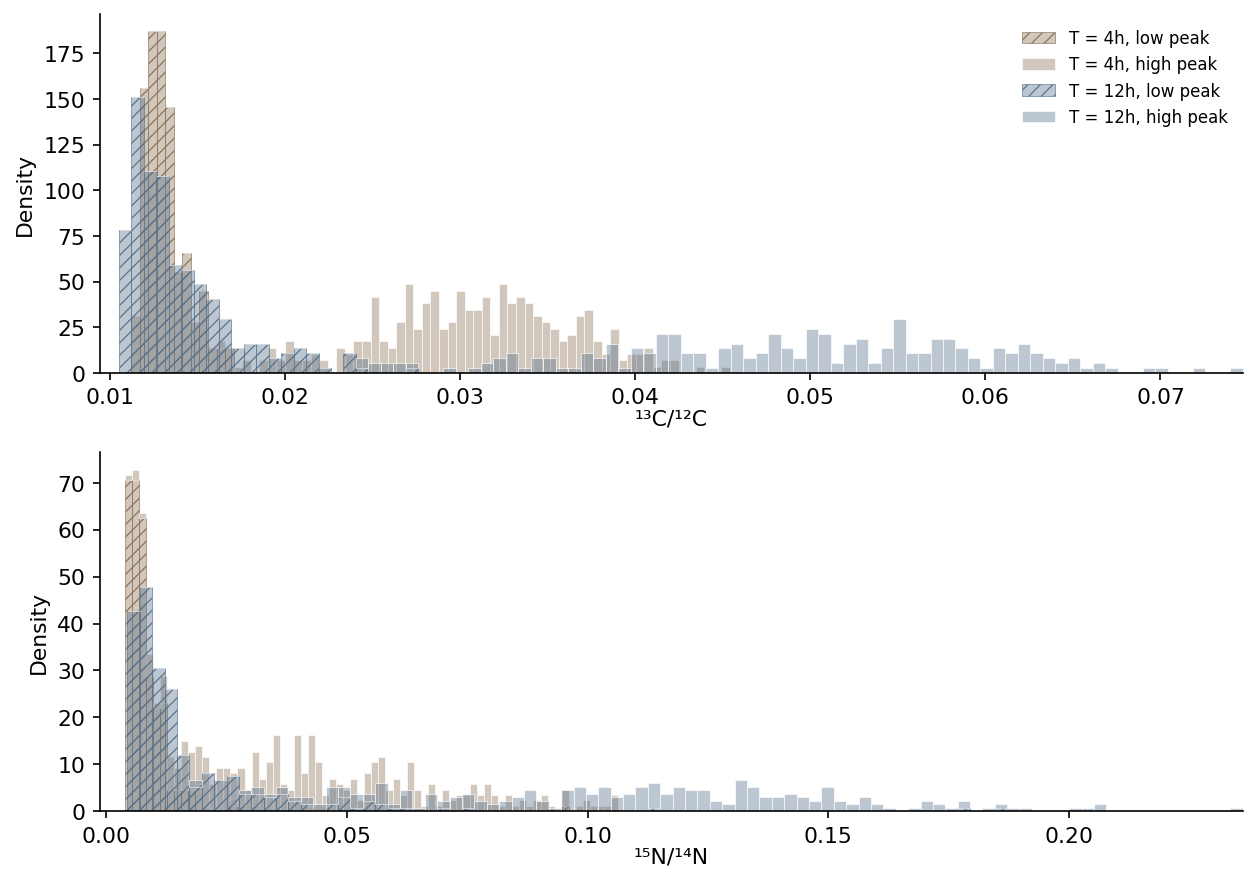

Carbon:
  Carbon low [C_low]: diff=-0.00080636, 95% CI=[-0.0013955, -0.00029761], p=0.0240
  Carbon high [C_high]: diff=-0.018252, 95% CI=[-0.020191, -0.016043], p=0.0000
Nitrogen:
  Nitrogen low [N_low]: diff=-0.0084012, 95% CI=[-0.011059, -0.0055203], p=0.0000
  Nitrogen high [N_high]: diff=-0.063435, 95% CI=[-0.070088, -0.056003], p=0.0000
FDR-corrected p-values: {'C_low': np.float64(0.024), 'C_high': np.float64(0.0), 'N_low': np.float64(0.0), 'N_high': np.float64(0.0)}


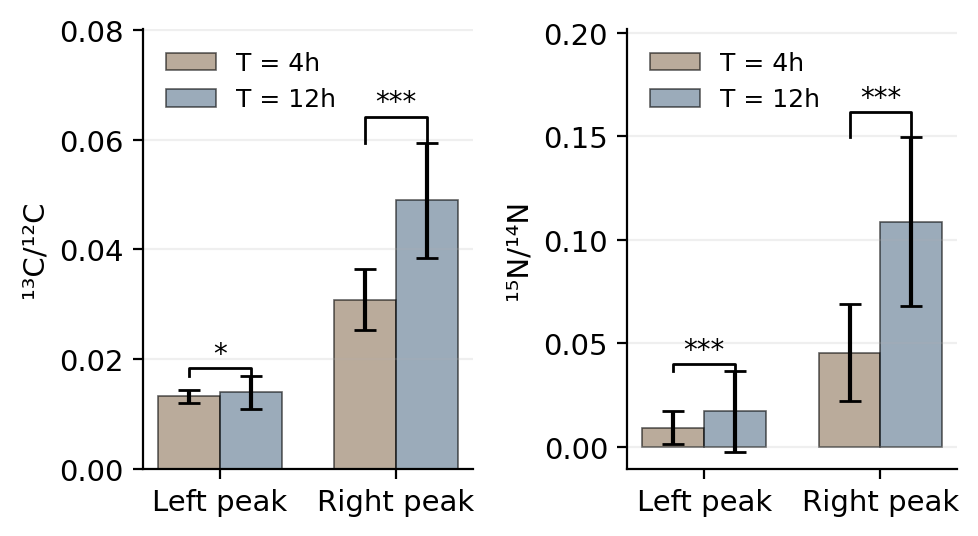

In [3]:
"""
Cluster log(C_ratio) vs log(N_ratio) into two groups for two timepoints (4h, 12h), and
check that BOTH ratios come out bimodal under the split.

Figure 1 - clustering diagnostic (3 rows x 2 cols, one column per timepoint):
  row 0: overlaid histograms of C_ratio for the two clusters
  row 1: overlaid histograms of N_ratio for the two clusters
  row 2: scatter of C_ratio vs N_ratio, colored by cluster

Figure 2 - C/N by timepoint (2 rows x 1 col, stacked):
  top:    histogram of C_ratio for 4h and 12h overlaid, one color per timepoint.
          Within each timepoint the bars are split by the GMM's two clusters
          (stacked): the low group is drawn hatched, the high group solid, so
          the total bar height is still the full timepoint histogram. No fitted
          curves are drawn.
  bottom: same, for N_ratio

Why this changed from plain k-means:
  - C_ratio and N_ratio don't have the same spread (N_ratio's range is often
    ~2-3x C_ratio's). Plain k-means on the raw log values lets whichever
    variable has more variance dominate the Euclidean distance, so the split
    mostly tracks N_ratio and C_ratio ends up smeared across both clusters
    (poor separation in the C_ratio marginal -> not bimodal). Fix: z-score
    both log-ratios (StandardScaler) before clustering so they contribute
    equally.
  - K-means also assumes round, equal-size, equal-variance clusters. Your
    data is an elongated, positively-correlated cloud (a tight low group +
    a more spread-out high group) - not what k-means is built for. A
    Gaussian Mixture Model (GMM) fits ellipses aligned with the actual
    covariance of each group and is the standard tool when you expect the
    data to be a mixture of ~2 (bimodal) populations. GMM is now the
    default; k-means is kept as an option for comparison.

Requires: numpy, pandas, matplotlib, scikit-learn, scipy, statsmodels
    pip install scikit-learn matplotlib pandas numpy scipy statsmodels
"""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.stats import norm
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.multitest import multipletests  # was missing, run_cluster_stats needs it

# ---- categorical colors (colorblind-safe adjacent pair) ----
COLOR_CLUSTER0 = "#2a78d6"  # blue   = "low" group
COLOR_CLUSTER1 = "#eb6834"  # orange = "high" group
CLUSTER_COLORS = [COLOR_CLUSTER0, COLOR_CLUSTER1]

# colors per timepoint, used only in the combined C/N-by-timepoint figure
# (that figure does NOT color by cluster, so it gets its own color map)
TIMEPOINT_COLORS = {"T4_rep2": "#2a78d6", "T12_rep2": "#eb6834"}


def cluster_log_ratios(df, method="gmm", n_clusters=2, random_state=42):
    """
    Compute log(C_ratio), log(N_ratio), standardize them, and split into
    n_clusters groups.

    method: "gmm" (default, recommended) or "kmeans".

    Clusters are relabeled so cluster 0 always has the lower mean
    (standardized logC + logN) -> "low" group, cluster 1 -> "high" group.
    This keeps colors/labels consistent across panels and datasets, since
    both GMM and k-means assign arbitrary label numbers each run.

    Returns (data, model, scaler) where data has columns
    [logC, logN, cluster].
    """
    logC = np.log(df["C_ratio"])
    logN = np.log(df["N_ratio"])
    data = pd.DataFrame({"logC": logC, "logN": logN})
    data = data.replace([np.inf, -np.inf], np.nan).dropna()
    data["C_ratio"] = df["C_ratio"]
    data["N_ratio"] = df["N_ratio"]

    scaler = StandardScaler()
    X = scaler.fit_transform(data[["logC", "logN"]])

    if method == "gmm":
        model = GaussianMixture(
            n_components=n_clusters, covariance_type="full",
            random_state=random_state, n_init=10,
        )
        labels = model.fit_predict(X)
    elif method == "kmeans":
        model = KMeans(n_clusters=n_clusters, random_state=random_state, n_init=10)
        labels = model.fit_predict(X)
    else:
        raise ValueError("method must be 'gmm' or 'kmeans'")

    # relabel by ascending mean score so 0 = low group, 1 = high group
    score = X.sum(axis=1)
    order = pd.Series(score, index=data.index).groupby(labels).mean().sort_values().index
    relabel = {old: new for new, old in enumerate(order)}
    data["cluster"] = [relabel[l] for l in labels]
    return data, model, scaler


def plot_scatter(ax, data, title):
    for cluster_id in sorted(data["cluster"].unique()):
        sub = data[data["cluster"] == cluster_id]
        ax.scatter(
            sub["C_ratio"], sub["N_ratio"],
            s=18, alpha=0.75,
            color=CLUSTER_COLORS[cluster_id],
            edgecolor="white", linewidth=0.3,
            label=f"Cluster {cluster_id}",
        )
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("¹³C/¹²C")
    ax.set_ylabel("¹⁵N/¹⁴N")
    ax.set_title(title)
    ax.legend(frameon=False, fontsize=8)


def plot_hist(ax, data, title, column, bins=70):
    for cluster_id in sorted(data["cluster"].unique()):
        sub = data[data["cluster"] == cluster_id]
        ax.hist(
            sub[column], bins=bins, alpha=0.55,
            color=CLUSTER_COLORS[cluster_id],
            edgecolor="white", linewidth=0.3,
            label=f"Cluster {cluster_id}",
        )
    xlabel = "¹³C/¹²C" if column == "C_ratio" else "¹⁵N/¹⁴N"
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Count")
    ax.set_title(title)
    ax.legend(frameon=False, fontsize=8)


CLUSTER_NAMES = ["low", "high"]
CLUSTER_HATCHES = ["////", None]  # cluster 0 (low peak) hatched, cluster 1 (high peak) solid
plt.rcParams["hatch.linewidth"] = 0.6


def plot_timepoint_histogram(ax, datasets, clustered, column, xlabel, show_legend=False):
    """
    Overlay histograms of `column` for every timepoint in `datasets`,
    colored by TIMEPOINT. Within each timepoint the bars are split by its
    two GMM clusters, stacked on top of each other with shared bin edges:
    low peak = hatched, high peak = solid fill (same timepoint color). The
    stack is normalized as a whole (density=True + stacked=True), so the
    outline of each timepoint is the same as the unsplit histogram.

    `clustered` is {name: data} as returned by cluster_log_ratios(df)[0],
    precomputed once per timepoint so it can be shared between the C and N
    panels.
    """
    bins = [70, 90]
    color4 = (0.55, 0.45, 0.35, 0.4)    # muted warm grey (taupe)  - fill
    color12 = (0.35, 0.45, 0.55, 0.4)   # muted cool grey (slate blue) - fill
    colors = [color4, color12]

    legend_handles = []
    for i, name in enumerate(datasets.keys()):
        data = clustered[name]
        vals_all = data[column]
        edges = np.histogram_bin_edges(vals_all, bins=bins[i])  # same bins for both clusters

        fill = colors[i]
        line = (*fill[:3], 1.0)  # opaque version of the timepoint color, for the hatch lines

        cluster_ids = sorted(data["cluster"].unique())
        vals_by_cluster = [data.loc[data["cluster"] == c, column] for c in cluster_ids]

        _, _, patch_groups = ax.hist(
            vals_by_cluster, bins=edges, density=True, stacked=True,
            color=[fill] * len(cluster_ids),
        )
        # matplotlib returns a single BarContainer (not a list) if there is only one cluster
        if len(cluster_ids) == 1:
            patch_groups = [patch_groups]

        for cluster_id, patches in zip(cluster_ids, patch_groups):
            hatch = CLUSTER_HATCHES[cluster_id]
            for p in patches:
                if hatch:
                    # hatch lines are drawn in the edge color
                    p.set_hatch(hatch)
                    p.set_edgecolor(line)
                    p.set_linewidth(0.3)
                else:
                    p.set_edgecolor("white")
                    p.set_linewidth(0.3)

        for cluster_id in cluster_ids:
            legend_handles.append(Patch(
                facecolor=fill,
                edgecolor=line if CLUSTER_HATCHES[cluster_id] else "white",
                hatch=CLUSTER_HATCHES[cluster_id], linewidth=0.3,
                label=f"{name}, {CLUSTER_NAMES[cluster_id]} peak",
            ))

    ax.set_xlabel(xlabel, labelpad=0.55)
    ax.set_ylabel("Density")
    ax.set_xlim(min(datasets['T = 4h'][column])-0.00002/min(datasets['T = 4h'][column]),
                max(datasets['T = 12h'][column]))
    if show_legend:
        ax.legend(handles=legend_handles, frameon=False, fontsize=8)


def plot_c_n_by_timepoint(datasets, method="gmm", outpath="c_n_by_timepoint.png"):
    """
    2-panel figure, stacked (2 rows x 1 col): top = C_ratio histograms for
    every timepoint in `datasets`, bottom = N_ratio histograms. One color per
    timepoint; within a timepoint the low/high GMM clusters are shown as
    hatched/solid stacked bars (see plot_timepoint_histogram).
    """
    # cluster each timepoint once, reused for both the C and N panels
    clustered = {name: cluster_log_ratios(df, method=method, n_clusters=2)[0]
                 for name, df in datasets.items()}

    fig, axes = plt.subplots(2, 1, figsize=(8.5, 6))
    plot_timepoint_histogram(axes[0], datasets, clustered, "C_ratio", "¹³C/¹²C", show_legend=True)
    plot_timepoint_histogram(axes[1], datasets, clustered, "N_ratio", "¹⁵N/¹⁴N")
    plt.tight_layout()
    plt.savefig(outpath, dpi=200)

    plt.show()

def cluster_gaussian_stats(data, column):
    """
    Gaussian fit (mean, std) of `column` for each cluster in an already-
    clustered `data` frame (as returned by cluster_log_ratios(df)[0]).
    Returns (means, stds), each a length-2 array ordered [low, high] --
    the same low/high ordering cluster_log_ratios already guarantees.
    """
    means = np.zeros(2)
    stds = np.zeros(2)
    for cluster_id in (0, 1):
        sub = data.loc[data["cluster"] == cluster_id, column]
        means[cluster_id], stds[cluster_id] = norm.fit(sub)
    return means, stds


def bootstrap_cluster_means(df, method="gmm", n_boot=500, random_state=0):
    """
    Resample `df` with replacement, redo the SAME joint (standardized
    logC, logN) GMM/k-means split used throughout this script
    (cluster_log_ratios), and record the resulting low/high cluster means
    of C_ratio and N_ratio. This captures clustering-fit uncertainty, not
    just point-assignment noise -- a bad bootstrap draw can flip which
    points land in which cluster entirely.

    Returns a dict of length-n_boot arrays: {"C_low", "C_high", "N_low",
    "N_high"} (NaN for any bootstrap draw where the fit failed or a
    cluster came out empty).
    """
    rng = np.random.default_rng(random_state)
    n = len(df)
    out = {k: np.full(n_boot, np.nan) for k in ("C_low", "C_high", "N_low", "N_high")}
    n_failed = 0
    for i in range(n_boot):
        idx = rng.integers(0, n, size=n)
        sample = df.iloc[idx].reset_index(drop=True)
        try:
            data, _, _ = cluster_log_ratios(sample, method=method, n_clusters=2, random_state=i)
            for cluster_id, tag in ((0, "low"), (1, "high")):
                sub = data.loc[data["cluster"] == cluster_id]
                if len(sub) > 1:
                    out[f"C_{tag}"][i] = sub["C_ratio"].mean()
                    out[f"N_{tag}"][i] = sub["N_ratio"].mean()
        except Exception:
            n_failed += 1
    if n_failed:
        print(f"  ({n_failed}/{n_boot} bootstrap fits failed/degenerate)")
    return out


def bootstrap_diff_pvalue(boot_a, boot_b, key, label=None, n_draws=2000, random_state=0):
    """
    Two-sided bootstrap p-value for whether the `key` cluster mean
    (e.g. "C_low") differs between two bootstrap distributions
    (from bootstrap_cluster_means). Draws random pairs from each
    distribution and reports the fraction of differences that cross zero.
    """
    rng = np.random.default_rng(random_state)
    a = boot_a[key]
    a = a[~np.isnan(a)]
    b = boot_b[key]
    b = b[~np.isnan(b)]
    diff = rng.choice(a, n_draws, replace=True) - rng.choice(b, n_draws, replace=True)
    p = min(2 * min((diff > 0).mean(), (diff < 0).mean()), 1.0)
    if label is not None:
        obs_diff = np.nanmean(a) - np.nanmean(b)
        ci_lo, ci_hi = np.percentile(diff, [2.5, 97.5])
        print(f"  {label} [{key}]: diff={obs_diff:.5g}, 95% CI=[{ci_lo:.5g}, {ci_hi:.5g}], p={p:.4f}")
    return p


def run_cluster_stats(datasets, method="gmm", n_boot=500, alpha=0.05):
    """
    Bootstrap-test each cluster's mean (C_low, C_high, N_low, N_high)
    between the two timepoints in `datasets`, then apply Benjamini-Hochberg
    FDR correction across all four tests. Returns a dict of FDR-corrected
    p-values keyed "C_low", "C_high", "N_low", "N_high".
    """
    names = list(datasets.keys())
    if len(names) != 2:
        raise ValueError("run_cluster_stats expects exactly two timepoints")
    name_a, name_b = names

    boot = {
        name: bootstrap_cluster_means(df, method=method, n_boot=n_boot, random_state=42 + i)
        for i, (name, df) in enumerate(datasets.items())
    }

    print("Carbon:")
    p_C_low = bootstrap_diff_pvalue(boot[name_a], boot[name_b], "C_low", label="Carbon low")
    p_C_high = bootstrap_diff_pvalue(boot[name_a], boot[name_b], "C_high", label="Carbon high")
    print("Nitrogen:")
    p_N_low = bootstrap_diff_pvalue(boot[name_a], boot[name_b], "N_low", label="Nitrogen low")
    p_N_high = bootstrap_diff_pvalue(boot[name_a], boot[name_b], "N_high", label="Nitrogen high")

    keys = ["C_low", "C_high", "N_low", "N_high"]
    raw_pvals = [p_C_low, p_C_high, p_N_low, p_N_high]
    _, pvals_corrected, _, _ = multipletests(raw_pvals, alpha=alpha, method="fdr_bh")
    print("FDR-corrected p-values:", dict(zip(keys, np.round(pvals_corrected, 4))))
    return dict(zip(keys, pvals_corrected))


def p_to_star(p):
    if p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    else:
        return "ns"


def add_sig_bracket(ax, x1, x2, y_top, p, gap=0.08):
    """Draw a significance bracket + star/ns label just above y_top."""
    y_line = y_top * (1 + gap)
    ax.plot([x1, x1, x2, x2], [y_top, y_line, y_line, y_top], lw=1, color="black")
    ax.text((x1 + x2) / 2, y_line, p_to_star(p), ha="center", va="bottom", fontsize=10)


def plot_cluster_stats_barplot(datasets, clustered, pvals, outpath="cluster_stats_barplot.png"):
    """
    1x2 bar plot of low/high cluster means (+- std) for C_ratio and
    N_ratio, comparing the two timepoints in `datasets`. Cluster stats come
    from `clustered` (the same joint GMM split used in the other figures);
    `pvals` is the dict returned by run_cluster_stats, used to draw
    significance brackets between the two timepoints for each cluster.
    """
    names = list(datasets.keys())
    name_a, name_b = names
    color4 = (0.55, 0.45, 0.35, 0.4)   # muted warm grey (taupe)
    color12 = (0.35, 0.45, 0.55, 0.4)   # muted cool grey (slate blue)
    color_a = color4
    color_b = color12

    means_C_a, stds_C_a = cluster_gaussian_stats(clustered[name_a], "C_ratio")
    means_C_b, stds_C_b = cluster_gaussian_stats(clustered[name_b], "C_ratio")
    means_N_a, stds_N_a = cluster_gaussian_stats(clustered[name_a], "N_ratio")
    means_N_b, stds_N_b = cluster_gaussian_stats(clustered[name_b], "N_ratio")

    x = np.arange(2)  # [low, high]
    width = 0.35
    fig, axes = plt.subplots(1, 2, figsize=(5, 2.8), dpi=200)

    def _panel(ax, means_a, stds_a, means_b, stds_b, ylabel, title, p_low, p_high):
        ax.bar(x - width / 2, means_a, width, yerr=stds_a, capsize=4, label=name_a,
               color=color_a, alpha=0.6, edgecolor="black", linewidth=0.6)
        ax.bar(x + width / 2, means_b, width, yerr=stds_b, capsize=4, label=name_b,
               color=color_b, alpha=0.6, edgecolor="black", linewidth=0.6)
        ax.set_xticks(x)
        ax.set_xticklabels(["Left peak", "Right peak"])
        ax.set_ylabel(ylabel)
        #ax.set_title(title)
        ax.legend(frameon=False, fontsize=9)
        ax.grid(axis="y", alpha=0.2)

        top_low = max(means_a[0] + stds_a[0], means_b[0] + stds_b[0])
        top_high = max(means_a[1] + stds_a[1], means_b[1] + stds_b[1])
        add_sig_bracket(ax, 0 - width / 2, 0 + width / 2, top_low, p_low)
        add_sig_bracket(ax, 1 - width / 2, 1 + width / 2, top_high, p_high)
        ax.set_ylim(top=max(top_low, top_high) * 1.35)

    _panel(axes[0], means_C_a, stds_C_a, means_C_b, stds_C_b,
           "¹³C/¹²C", "Carbon cluster means", pvals["C_low"], pvals["C_high"])
    _panel(axes[1], means_N_a, stds_N_a, means_N_b, stds_N_b,
           "¹⁵N/¹⁴N", "Nitrogen cluster means", pvals["N_low"], pvals["N_high"])

    plt.tight_layout()
    plt.savefig(outpath, dpi=200)
    plt.show()


def main(t4_rep2, t12_rep2, method="gmm", n_boot=100):
    datasets = {"T = 4h": t4_rep2, "T = 12h": t12_rep2}

    # --- Figure 1: clustering diagnostic, one column per timepoint ---
    #fig, axes = plt.subplots(3, 2, figsize=(11, 11))
    #for col_idx, (name, df) in enumerate(datasets.items()):
    #    data, model, scaler = cluster_log_ratios(df, method=method, n_clusters=2)
    #    plot_hist(axes[0, col_idx], data, f"{name}: C_ratio by cluster", column="C_ratio")
    #    plot_hist(axes[1, col_idx], data, f"{name}: N_ratio by cluster", column="N_ratio")
    #    plot_scatter(axes[2, col_idx], data, f"{name}")
    #plt.tight_layout()
    #plt.savefig("clusters_figure.png", dpi=200)
    #plt.show()
    clustered = {name: cluster_log_ratios(df, method=method, n_clusters=2)[0]
                 for name, df in datasets.items()}

    # --- Figure 2: C and N histograms across timepoints, bars split by cluster ---
    plot_c_n_by_timepoint(datasets, method=method, outpath="c_n_by_timepoint.png")

    # --- Figure 3: cluster means bar plot, 4h vs 12h, with bootstrap significance ---
    pvals = run_cluster_stats(datasets, method=method, n_boot=n_boot)
    plot_cluster_stats_barplot(datasets, clustered, pvals, outpath="cluster_stats_barplot.png")


if __name__ == "__main__":
    # replace with your actual dataframes, e.g. loaded via pd.read_csv(...)
    blank = load(("0h", "blank"))
    t4_rep2 = load(("4h", "rep2"))
    t12_rep2 = load(("12h", "rep2"))

    # thresholds from the blank distribution
    c_thresh = blank["C_ratio"].mean() - blank["C_ratio"].std()
    n_thresh = blank["N_ratio"].mean() - blank["N_ratio"].std()

    def filter_below_blank(df, c_thresh, n_thresh):
        return df[(df["C_ratio"] >= c_thresh) & (df["N_ratio"] >= n_thresh)]

    t4_rep2_filt = filter_below_blank(t4_rep2, c_thresh, n_thresh)
    t12_rep2_filt = filter_below_blank(t12_rep2, c_thresh, n_thresh)

    def save_filtered(df, timepoint, replicate):
        filename = f"experiments/new_data/replicates/{timepoint}_{replicate}_filtered.csv"
        df.to_csv(filename, index=False)
        print(f"Saved {filename} ({len(df)} rows)")

    save_filtered(t4_rep2_filt, "4h", "rep2")
    save_filtered(t12_rep2_filt, "12h", "rep2")

    main(t4_rep2_filt, t12_rep2_filt, method="gmm")

Saved experiments/new_data/replicates/4h_rep2_filtered.csv (591 rows)
Saved experiments/new_data/replicates/12h_rep2_filtered.csv (520 rows)


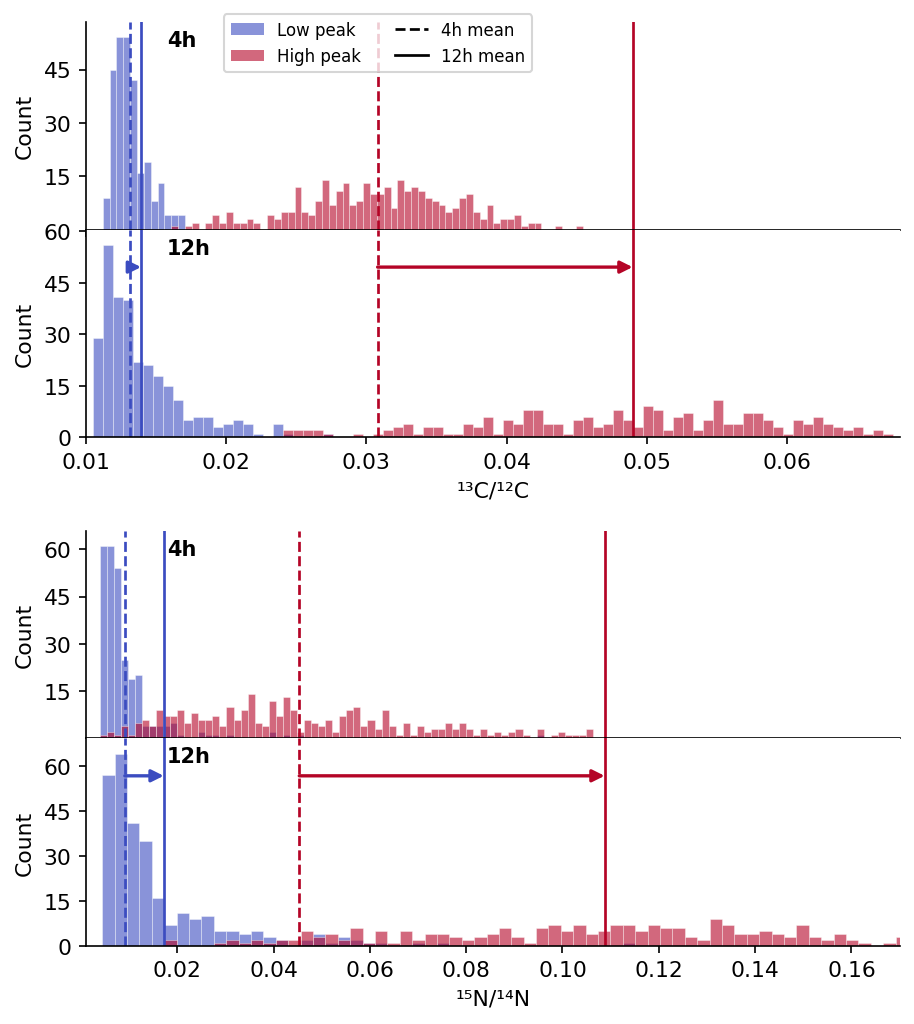

Carbon:
  Carbon low [C_low]: diff=-0.00080636, 95% CI=[-0.0013955, -0.00029761], p=0.0240
  Carbon high [C_high]: diff=-0.018252, 95% CI=[-0.020191, -0.016043], p=0.0000
Nitrogen:
  Nitrogen low [N_low]: diff=-0.0084012, 95% CI=[-0.011059, -0.0055203], p=0.0000
  Nitrogen high [N_high]: diff=-0.063435, 95% CI=[-0.070088, -0.056003], p=0.0000
FDR-corrected p-values: {'C_low': np.float64(0.024), 'C_high': np.float64(0.0), 'N_low': np.float64(0.0), 'N_high': np.float64(0.0)}


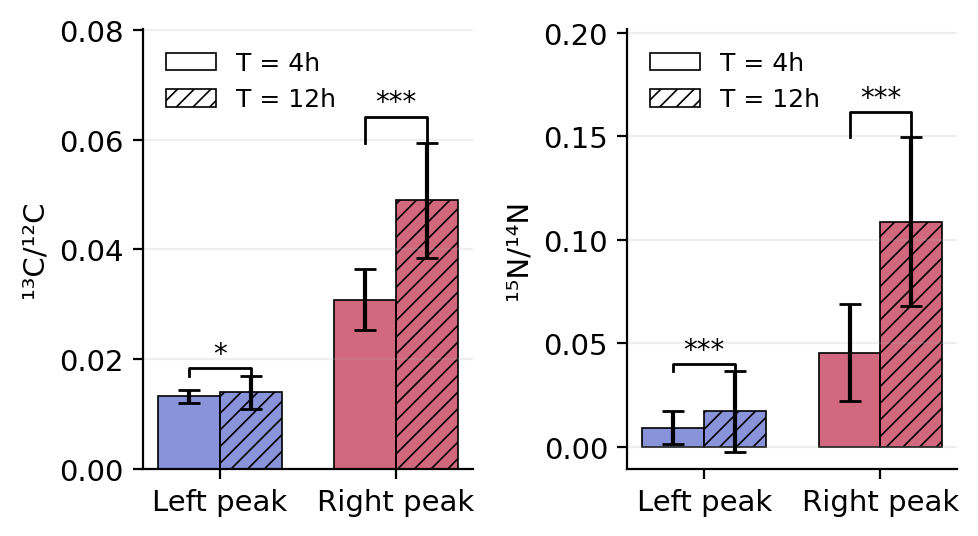

In [15]:
"""
Cluster log(C_ratio) vs log(N_ratio) into two groups for two timepoints (4h, 12h), and
check that BOTH ratios come out bimodal under the split.

Figure 1 - clustering diagnostic (3 rows x 2 cols, one column per timepoint):
  row 0: overlaid histograms of C_ratio for the two clusters
  row 1: overlaid histograms of N_ratio for the two clusters
  row 2: scatter of C_ratio vs N_ratio, colored by cluster

Figure 2 - C/N by timepoint (2 rows x 1 col, stacked):
  top:    histogram of C_ratio for 4h and 12h overlaid, one color per timepoint.
          Within each timepoint the bars are split by the GMM's two clusters
          (stacked): the low group is drawn hatched, the high group solid, so
          the total bar height is still the full timepoint histogram. No fitted
          curves are drawn.
  bottom: same, for N_ratio

Why this changed from plain k-means:
  - C_ratio and N_ratio don't have the same spread (N_ratio's range is often
    ~2-3x C_ratio's). Plain k-means on the raw log values lets whichever
    variable has more variance dominate the Euclidean distance, so the split
    mostly tracks N_ratio and C_ratio ends up smeared across both clusters
    (poor separation in the C_ratio marginal -> not bimodal). Fix: z-score
    both log-ratios (StandardScaler) before clustering so they contribute
    equally.
  - K-means also assumes round, equal-size, equal-variance clusters. Your
    data is an elongated, positively-correlated cloud (a tight low group +
    a more spread-out high group) - not what k-means is built for. A
    Gaussian Mixture Model (GMM) fits ellipses aligned with the actual
    covariance of each group and is the standard tool when you expect the
    data to be a mixture of ~2 (bimodal) populations. GMM is now the
    default; k-means is kept as an option for comparison.

Requires: numpy, pandas, matplotlib, scikit-learn, scipy, statsmodels
    pip install scikit-learn matplotlib pandas numpy scipy statsmodels
"""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.stats import norm
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.multitest import multipletests  # was missing, run_cluster_stats needs it

# ---- categorical colors (colorblind-safe adjacent pair) ----
COLOR_CLUSTER0 = "#2a78d6"  # blue   = "low" group
COLOR_CLUSTER1 = "#eb6834"  # orange = "high" group
CLUSTER_COLORS = [COLOR_CLUSTER0, COLOR_CLUSTER1]

# colors per timepoint, used only in the combined C/N-by-timepoint figure
# (that figure does NOT color by cluster, so it gets its own color map)
TIMEPOINT_COLORS = {"T4_rep2": "#2a78d6", "T12_rep2": "#eb6834"}


def cluster_log_ratios(df, method="gmm", n_clusters=2, random_state=42):
    """
    Compute log(C_ratio), log(N_ratio), standardize them, and split into
    n_clusters groups.

    method: "gmm" (default, recommended) or "kmeans".

    Clusters are relabeled so cluster 0 always has the lower mean
    (standardized logC + logN) -> "low" group, cluster 1 -> "high" group.
    This keeps colors/labels consistent across panels and datasets, since
    both GMM and k-means assign arbitrary label numbers each run.

    Returns (data, model, scaler) where data has columns
    [logC, logN, cluster].
    """
    logC = np.log(df["C_ratio"])
    logN = np.log(df["N_ratio"])
    data = pd.DataFrame({"logC": logC, "logN": logN})
    data = data.replace([np.inf, -np.inf], np.nan).dropna()
    data["C_ratio"] = df["C_ratio"]
    data["N_ratio"] = df["N_ratio"]

    scaler = StandardScaler()
    X = scaler.fit_transform(data[["logC", "logN"]])

    if method == "gmm":
        model = GaussianMixture(
            n_components=n_clusters, covariance_type="full",
            random_state=random_state, n_init=10,
        )
        labels = model.fit_predict(X)
    elif method == "kmeans":
        model = KMeans(n_clusters=n_clusters, random_state=random_state, n_init=10)
        labels = model.fit_predict(X)
    else:
        raise ValueError("method must be 'gmm' or 'kmeans'")

    # relabel by ascending mean score so 0 = low group, 1 = high group
    score = X.sum(axis=1)
    order = pd.Series(score, index=data.index).groupby(labels).mean().sort_values().index
    relabel = {old: new for new, old in enumerate(order)}
    data["cluster"] = [relabel[l] for l in labels]
    return data, model, scaler


def plot_scatter(ax, data, title):
    for cluster_id in sorted(data["cluster"].unique()):
        sub = data[data["cluster"] == cluster_id]
        ax.scatter(
            sub["C_ratio"], sub["N_ratio"],
            s=18, alpha=0.75,
            color=CLUSTER_COLORS[cluster_id],
            edgecolor="white", linewidth=0.3,
            label=f"Cluster {cluster_id}",
        )
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("¹³C/¹²C")
    ax.set_ylabel("¹⁵N/¹⁴N")
    ax.set_title(title)
    ax.legend(frameon=False, fontsize=8)


def plot_hist(ax, data, title, column, bins=70):
    for cluster_id in sorted(data["cluster"].unique()):
        sub = data[data["cluster"] == cluster_id]
        ax.hist(
            sub[column], bins=bins, alpha=0.55,
            color=CLUSTER_COLORS[cluster_id],
            edgecolor="white", linewidth=0.3,
            label=f"Cluster {cluster_id}",
        )
    xlabel = "¹³C/¹²C" if column == "C_ratio" else "¹⁵N/¹⁴N"
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Count")
    ax.set_title(title)
    ax.legend(frameon=False, fontsize=8)


CLUSTER_NAMES = ["low", "high"]
CLUSTER_HATCHES = ["////", None]  # cluster 0 (low peak) hatched, cluster 1 (high peak) solid
plt.rcParams["hatch.linewidth"] = 0.6


def plot_timepoint_histogram(ax, datasets, clustered, column, xlabel, show_legend=False):
    """
    Overlay histograms of `column` for every timepoint in `datasets`,
    colored by TIMEPOINT. Within each timepoint the bars are split by its
    two GMM clusters, stacked on top of each other with shared bin edges:
    low peak = hatched, high peak = solid fill (same timepoint color). The
    stack is normalized as a whole (density=True + stacked=True), so the
    outline of each timepoint is the same as the unsplit histogram.

    `clustered` is {name: data} as returned by cluster_log_ratios(df)[0],
    precomputed once per timepoint so it can be shared between the C and N
    panels.
    """
    bins = [70, 90]
    color4 = (0.55, 0.45, 0.35, 0.4)    # muted warm grey (taupe)  - fill
    color12 = (0.35, 0.45, 0.55, 0.4)   # muted cool grey (slate blue) - fill
    colors = [color4, color12]

    legend_handles = []
    for i, name in enumerate(datasets.keys()):
        data = clustered[name]
        vals_all = data[column]
        edges = np.histogram_bin_edges(vals_all, bins=bins[i])  # same bins for both clusters

        fill = colors[i]
        line = (*fill[:3], 1.0)  # opaque version of the timepoint color, for the hatch lines

        cluster_ids = sorted(data["cluster"].unique())
        vals_by_cluster = [data.loc[data["cluster"] == c, column] for c in cluster_ids]

        _, _, patch_groups = ax.hist(
            vals_by_cluster, bins=edges, density=True, stacked=True,
            color=[fill] * len(cluster_ids),
        )
        # matplotlib returns a single BarContainer (not a list) if there is only one cluster
        if len(cluster_ids) == 1:
            patch_groups = [patch_groups]

        for cluster_id, patches in zip(cluster_ids, patch_groups):
            hatch = CLUSTER_HATCHES[cluster_id]
            for p in patches:
                if hatch:
                    # hatch lines are drawn in the edge color
                    p.set_hatch(hatch)
                    p.set_edgecolor(line)
                    p.set_linewidth(0.3)
                else:
                    p.set_edgecolor("white")
                    p.set_linewidth(0.3)

        for cluster_id in cluster_ids:
            legend_handles.append(Patch(
                facecolor=fill,
                edgecolor=line if CLUSTER_HATCHES[cluster_id] else "white",
                hatch=CLUSTER_HATCHES[cluster_id], linewidth=0.3,
                label=f"{name}, {CLUSTER_NAMES[cluster_id]} peak",
            ))

    ax.set_xlabel(xlabel, labelpad=0.55)
    ax.set_ylabel("Density")
    ax.set_xlim(min(datasets['T = 4h'][column])-0.00002/min(datasets['T = 4h'][column]),
                max(datasets['T = 12h'][column]))
    if show_legend:
        ax.legend(handles=legend_handles, frameon=False, fontsize=8)


def plot_c_n_by_timepoint(datasets, method="gmm", outpath="c_n_by_timepoint.png"):
    """
    2-panel figure, stacked (2 rows x 1 col): top = C_ratio histograms for
    every timepoint in `datasets`, bottom = N_ratio histograms. One color per
    timepoint; within a timepoint the low/high GMM clusters are shown as
    hatched/solid stacked bars (see plot_timepoint_histogram).
    """
    # cluster each timepoint once, reused for both the C and N panels
    clustered = {name: cluster_log_ratios(df, method=method, n_clusters=2)[0]
                 for name, df in datasets.items()}

    fig, axes = plt.subplots(2, 1, figsize=(8.5, 6))
    plot_timepoint_histogram(axes[0], datasets, clustered, "C_ratio", "¹³C/¹²C", show_legend=True)
    plot_timepoint_histogram(axes[1], datasets, clustered, "N_ratio", "¹⁵N/¹⁴N")
    plt.tight_layout()
    plt.savefig(outpath, dpi=200)

    plt.show()

# cluster colors for the 4-panel figure: the two extremes of the coolwarm colormap
COOLWARM_LOW = plt.get_cmap("coolwarm")(0.0)   # blue = low peak
COOLWARM_HIGH = plt.get_cmap("coolwarm")(1.0)  # red  = high peak
COOLWARM_CLUSTER_COLORS = [COOLWARM_LOW, COOLWARM_HIGH]


MEAN_LINESTYLES = {"T = 4h": "--", "T = 12h": "-"}  # 4h mean dashed, 12h mean solid


def plot_cluster_hist_panel(ax, data, column, label, bins=70, headroom=1.08):
    """
    Overlaid histograms of `column` for the two GMM clusters of ONE
    timepoint, sharing the same bin edges. Low peak = coolwarm blue,
    high peak = coolwarm red. The timepoint is written in the top-left corner.
    Returns the mean of each cluster, ordered [low, high].
    """
    edges = np.histogram_bin_edges(data[column], bins=bins)
    means = []
    for cluster_id in sorted(data["cluster"].unique()):
        sub = data.loc[data["cluster"] == cluster_id, column]
        ax.hist(
            sub, bins=edges, alpha=0.6,
            color=COOLWARM_CLUSTER_COLORS[cluster_id],
            edgecolor="white", linewidth=0.3,
        )
        means.append(sub.mean())
    ax.text(0.1, 0.96, label, transform=ax.transAxes,
            ha="left", va="top", fontsize=10, fontweight="bold")
    ax.set_ylabel("Count")
    ax.set_ylim(0, ax.get_ylim()[1] / 1.05 * headroom)  # autoscale adds 5%; replace with `headroom`
    return means


def plot_c_n_4panel(datasets, clustered, outpath="c_n_4panel.png",
                    c_xlim=(0.01, 0.068), n_xlim=(0.001, 0.17)):
    """
    4 rows x 1 col: C at 4h, C at 12h, N at 4h, N at 12h. Each panel shows
    that timepoint's two GMM clusters (blue = low peak, red = high peak).
    The 4h and 12h panels of each element touch and share an x-axis.

    For every peak, the 4h mean (dashed) and the 12h mean (solid) are drawn
    as vertical lines running through BOTH panels of that element, and an
    arrow in the 12h panel goes from the 4h mean to the 12h mean, showing
    how the peak moves between 4h and 12h.
    """
    from matplotlib.lines import Line2D

    name4, name12 = "T = 4h", "T = 12h"
    fig = plt.figure(figsize=(7, 8))
    # rows: C 4h, C 12h, spacer, N 4h, N 12h -- hspace=0 so each pair touches
    gs = fig.add_gridspec(5, 1, height_ratios=[1, 1, 0.45, 1, 1], hspace=0)
    ax_c4 = fig.add_subplot(gs[0])
    ax_c12 = fig.add_subplot(gs[1], sharex=ax_c4)
    ax_n4 = fig.add_subplot(gs[3])
    ax_n12 = fig.add_subplot(gs[4], sharex=ax_n4)

    pairs = [
        (ax_c4, ax_c12, "C_ratio", "¹³C/¹²C", c_xlim),
        (ax_n4, ax_n12, "N_ratio", "¹⁵N/¹⁴N", n_xlim),
    ]
    for ax4, ax12, column, xlabel, xlim in pairs:
        means4 = plot_cluster_hist_panel(ax4, clustered[name4], column, "4h", bins=70)
        means12 = plot_cluster_hist_panel(ax12, clustered[name12], column, "12h", bins=90)

        for cluster_id, (mu4, mu12) in enumerate(zip(means4, means12)):
            color = COOLWARM_CLUSTER_COLORS[cluster_id]
            # each mean line runs through both panels of this element
            for ax in (ax4, ax12):
                ax.axvline(mu4, color=color, linestyle=MEAN_LINESTYLES[name4], linewidth=1.3)
                ax.axvline(mu12, color=color, linestyle=MEAN_LINESTYLES[name12], linewidth=1.3)
            # arrow from the 4h mean to the 12h mean, near the top of the 12h panel
            ax12.annotate(
                "", xy=(mu12, 0.82), xytext=(mu4, 0.82),
                xycoords=("data", "axes fraction"), textcoords=("data", "axes fraction"),
                arrowprops=dict(arrowstyle="-|>", color=color, lw=1.6,
                                shrinkA=0, shrinkB=0, mutation_scale=12),
            )

        ax4.set_xlim(xlim)  # shared x, so this sets the 12h panel too
        ax4.tick_params(labelbottom=False)
        ax12.set_xlabel(xlabel)
        # avoid the top y tick of the 12h panel colliding with the 4h panel above
        from matplotlib.ticker import MaxNLocator
        ax12.yaxis.set_major_locator(MaxNLocator(nbins=5, prune="upper"))
        ax4.yaxis.set_major_locator(MaxNLocator(nbins=5, prune="lower"))

    legend_handles = [
        Patch(facecolor=COOLWARM_LOW, alpha=0.6, label="Low peak"),
        Patch(facecolor=COOLWARM_HIGH, alpha=0.6, label="High peak"),
        Line2D([], [], color="black", linestyle=MEAN_LINESTYLES[name4], lw=1.3, label="4h mean"),
        Line2D([], [], color="black", linestyle=MEAN_LINESTYLES[name12], lw=1.3, label="12h mean"),
    ]
    ax_c4.legend(handles=legend_handles, frameon=True, fontsize=8,
                 loc=(0.17,0.76), ncol=2)

    fig.align_ylabels()
    plt.savefig(outpath, dpi=200, bbox_inches="tight")
    plt.show()


def cluster_gaussian_stats(data, column):
    """
    Gaussian fit (mean, std) of `column` for each cluster in an already-
    clustered `data` frame (as returned by cluster_log_ratios(df)[0]).
    Returns (means, stds), each a length-2 array ordered [low, high] --
    the same low/high ordering cluster_log_ratios already guarantees.
    """
    means = np.zeros(2)
    stds = np.zeros(2)
    for cluster_id in (0, 1):
        sub = data.loc[data["cluster"] == cluster_id, column]
        means[cluster_id], stds[cluster_id] = norm.fit(sub)
    return means, stds


def bootstrap_cluster_means(df, method="gmm", n_boot=500, random_state=0):
    """
    Resample `df` with replacement, redo the SAME joint (standardized
    logC, logN) GMM/k-means split used throughout this script
    (cluster_log_ratios), and record the resulting low/high cluster means
    of C_ratio and N_ratio. This captures clustering-fit uncertainty, not
    just point-assignment noise -- a bad bootstrap draw can flip which
    points land in which cluster entirely.

    Returns a dict of length-n_boot arrays: {"C_low", "C_high", "N_low",
    "N_high"} (NaN for any bootstrap draw where the fit failed or a
    cluster came out empty).
    """
    rng = np.random.default_rng(random_state)
    n = len(df)
    out = {k: np.full(n_boot, np.nan) for k in ("C_low", "C_high", "N_low", "N_high")}
    n_failed = 0
    for i in range(n_boot):
        idx = rng.integers(0, n, size=n)
        sample = df.iloc[idx].reset_index(drop=True)
        try:
            data, _, _ = cluster_log_ratios(sample, method=method, n_clusters=2, random_state=i)
            for cluster_id, tag in ((0, "low"), (1, "high")):
                sub = data.loc[data["cluster"] == cluster_id]
                if len(sub) > 1:
                    out[f"C_{tag}"][i] = sub["C_ratio"].mean()
                    out[f"N_{tag}"][i] = sub["N_ratio"].mean()
        except Exception:
            n_failed += 1
    if n_failed:
        print(f"  ({n_failed}/{n_boot} bootstrap fits failed/degenerate)")
    return out


def bootstrap_diff_pvalue(boot_a, boot_b, key, label=None, n_draws=2000, random_state=0):
    """
    Two-sided bootstrap p-value for whether the `key` cluster mean
    (e.g. "C_low") differs between two bootstrap distributions
    (from bootstrap_cluster_means). Draws random pairs from each
    distribution and reports the fraction of differences that cross zero.
    """
    rng = np.random.default_rng(random_state)
    a = boot_a[key]
    a = a[~np.isnan(a)]
    b = boot_b[key]
    b = b[~np.isnan(b)]
    diff = rng.choice(a, n_draws, replace=True) - rng.choice(b, n_draws, replace=True)
    p = min(2 * min((diff > 0).mean(), (diff < 0).mean()), 1.0)
    if label is not None:
        obs_diff = np.nanmean(a) - np.nanmean(b)
        ci_lo, ci_hi = np.percentile(diff, [2.5, 97.5])
        print(f"  {label} [{key}]: diff={obs_diff:.5g}, 95% CI=[{ci_lo:.5g}, {ci_hi:.5g}], p={p:.4f}")
    return p


def run_cluster_stats(datasets, method="gmm", n_boot=500, alpha=0.05):
    """
    Bootstrap-test each cluster's mean (C_low, C_high, N_low, N_high)
    between the two timepoints in `datasets`, then apply Benjamini-Hochberg
    FDR correction across all four tests. Returns a dict of FDR-corrected
    p-values keyed "C_low", "C_high", "N_low", "N_high".
    """
    names = list(datasets.keys())
    if len(names) != 2:
        raise ValueError("run_cluster_stats expects exactly two timepoints")
    name_a, name_b = names

    boot = {
        name: bootstrap_cluster_means(df, method=method, n_boot=n_boot, random_state=42 + i)
        for i, (name, df) in enumerate(datasets.items())
    }

    print("Carbon:")
    p_C_low = bootstrap_diff_pvalue(boot[name_a], boot[name_b], "C_low", label="Carbon low")
    p_C_high = bootstrap_diff_pvalue(boot[name_a], boot[name_b], "C_high", label="Carbon high")
    print("Nitrogen:")
    p_N_low = bootstrap_diff_pvalue(boot[name_a], boot[name_b], "N_low", label="Nitrogen low")
    p_N_high = bootstrap_diff_pvalue(boot[name_a], boot[name_b], "N_high", label="Nitrogen high")

    keys = ["C_low", "C_high", "N_low", "N_high"]
    raw_pvals = [p_C_low, p_C_high, p_N_low, p_N_high]
    _, pvals_corrected, _, _ = multipletests(raw_pvals, alpha=alpha, method="fdr_bh")
    print("FDR-corrected p-values:", dict(zip(keys, np.round(pvals_corrected, 4))))
    return dict(zip(keys, pvals_corrected))


def p_to_star(p):
    if p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    else:
        return "ns"


def add_sig_bracket(ax, x1, x2, y_top, p, gap=0.08):
    """Draw a significance bracket + star/ns label just above y_top."""
    y_line = y_top * (1 + gap)
    ax.plot([x1, x1, x2, x2], [y_top, y_line, y_line, y_top], lw=1, color="black")
    ax.text((x1 + x2) / 2, y_line, p_to_star(p), ha="center", va="bottom", fontsize=10)


def plot_cluster_stats_barplot(datasets, clustered, pvals, outpath="cluster_stats_barplot.png"):
    """
    1x2 bar plot of low/high cluster means (+- std) for C_ratio and
    N_ratio, comparing the two timepoints in `datasets`. Cluster stats come
    from `clustered` (the same joint GMM split used in the other figures);
    `pvals` is the dict returned by run_cluster_stats, used to draw
    significance brackets between the two timepoints for each cluster.
    """
    names = list(datasets.keys())
    name_a, name_b = names
    # color = peak (left/low = coolwarm blue, right/high = coolwarm red),
    # pattern = timepoint (first timepoint plain, second timepoint hatched)
    peak_fills = [(*COOLWARM_LOW[:3], 0.6), (*COOLWARM_HIGH[:3], 0.6)]
    hatch_b = "////"
    plt.rcParams["hatch.linewidth"] = 0.6

    means_C_a, stds_C_a = cluster_gaussian_stats(clustered[name_a], "C_ratio")
    means_C_b, stds_C_b = cluster_gaussian_stats(clustered[name_b], "C_ratio")
    means_N_a, stds_N_a = cluster_gaussian_stats(clustered[name_a], "N_ratio")
    means_N_b, stds_N_b = cluster_gaussian_stats(clustered[name_b], "N_ratio")

    x = np.arange(2)  # [low, high]
    width = 0.35
    fig, axes = plt.subplots(1, 2, figsize=(5, 2.8), dpi=200)

    def _panel(ax, means_a, stds_a, means_b, stds_b, ylabel, title, p_low, p_high):
        ax.bar(x - width / 2, means_a, width, yerr=stds_a, capsize=4,
               color=peak_fills, edgecolor="black", linewidth=0.6)
        ax.bar(x + width / 2, means_b, width, yerr=stds_b, capsize=4,
               color=peak_fills, edgecolor="black", linewidth=0.6, hatch=hatch_b)
        ax.set_xticks(x)
        ax.set_xticklabels(["Left peak", "Right peak"])
        ax.set_ylabel(ylabel)
        #ax.set_title(title)
        ax.legend(handles=[
            Patch(facecolor="white", edgecolor="black", linewidth=0.6, label=name_a),
            Patch(facecolor="white", edgecolor="black", linewidth=0.6, hatch=hatch_b, label=name_b),
        ], frameon=False, fontsize=9)
        ax.grid(axis="y", alpha=0.2)

        top_low = max(means_a[0] + stds_a[0], means_b[0] + stds_b[0])
        top_high = max(means_a[1] + stds_a[1], means_b[1] + stds_b[1])
        add_sig_bracket(ax, 0 - width / 2, 0 + width / 2, top_low, p_low)
        add_sig_bracket(ax, 1 - width / 2, 1 + width / 2, top_high, p_high)
        ax.set_ylim(top=max(top_low, top_high) * 1.35)

    _panel(axes[0], means_C_a, stds_C_a, means_C_b, stds_C_b,
           "¹³C/¹²C", "Carbon cluster means", pvals["C_low"], pvals["C_high"])
    _panel(axes[1], means_N_a, stds_N_a, means_N_b, stds_N_b,
           "¹⁵N/¹⁴N", "Nitrogen cluster means", pvals["N_low"], pvals["N_high"])

    plt.tight_layout()
    plt.savefig(outpath, dpi=200)
    plt.show()


def main(t4_rep2, t12_rep2, method="gmm", n_boot=100):
    datasets = {"T = 4h": t4_rep2, "T = 12h": t12_rep2}

    # --- Figure 1: clustering diagnostic, one column per timepoint ---
    #fig, axes = plt.subplots(3, 2, figsize=(11, 11))
    #for col_idx, (name, df) in enumerate(datasets.items()):
    #    data, model, scaler = cluster_log_ratios(df, method=method, n_clusters=2)
    #    plot_hist(axes[0, col_idx], data, f"{name}: C_ratio by cluster", column="C_ratio")
    #    plot_hist(axes[1, col_idx], data, f"{name}: N_ratio by cluster", column="N_ratio")
    #    plot_scatter(axes[2, col_idx], data, f"{name}")
    #plt.tight_layout()
    #plt.savefig("clusters_figure.png", dpi=200)
    #plt.show()
    clustered = {name: cluster_log_ratios(df, method=method, n_clusters=2)[0]
                 for name, df in datasets.items()}

    # --- Figure 2: C and N histograms across timepoints, bars split by cluster ---

    # --- Figure 2b: 4 panels (C 4h, C 12h, N 4h, N 12h), clusters in coolwarm blue/red ---
    plot_c_n_4panel(datasets, clustered, outpath="c_n_4panel.png")

    # --- Figure 3: cluster means bar plot, 4h vs 12h, with bootstrap significance ---
    pvals = run_cluster_stats(datasets, method=method, n_boot=n_boot)
    plot_cluster_stats_barplot(datasets, clustered, pvals, outpath="cluster_stats_barplot.png")


if __name__ == "__main__":
    # replace with your actual dataframes, e.g. loaded via pd.read_csv(...)
    blank = load(("0h", "blank"))
    t4_rep2 = load(("4h", "rep2"))
    t12_rep2 = load(("12h", "rep2"))

    # thresholds from the blank distribution
    c_thresh = blank["C_ratio"].mean() - blank["C_ratio"].std()
    n_thresh = blank["N_ratio"].mean() - blank["N_ratio"].std()

    def filter_below_blank(df, c_thresh, n_thresh):
        return df[(df["C_ratio"] >= c_thresh) & (df["N_ratio"] >= n_thresh)]

    t4_rep2_filt = filter_below_blank(t4_rep2, c_thresh, n_thresh)
    t12_rep2_filt = filter_below_blank(t12_rep2, c_thresh, n_thresh)

    def save_filtered(df, timepoint, replicate):
        filename = f"experiments/new_data/replicates/{timepoint}_{replicate}_filtered.csv"
        df.to_csv(filename, index=False)
        print(f"Saved {filename} ({len(df)} rows)")

    save_filtered(t4_rep2_filt, "4h", "rep2")
    save_filtered(t12_rep2_filt, "12h", "rep2")

    main(t4_rep2_filt, t12_rep2_filt, method="gmm")

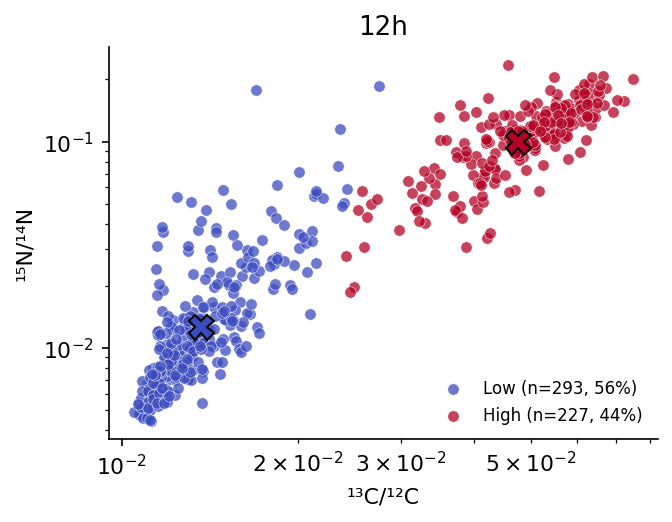

In [25]:
"""
2D scatter of the GMM clustering for the 12h timepoint: 13C/12C vs 15N/14N,
each cell colored by cluster (low peak = coolwarm blue, high peak = coolwarm red).

The clustering is the same one used in cluster_c_n_ratios.py: log both
ratios, z-score them (StandardScaler), fit a 2-component full-covariance GMM,
and relabel so cluster 0 = low group, cluster 1 = high group.

The GMM component center of each cluster is marked with an X. Axes are
log-log with standard decade ticks (10^-2, 10^-1, ...).

Requires: numpy, pandas, matplotlib, scikit-learn
"""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, LogFormatterSciNotation, NullFormatter, FuncFormatter

X_MINOR_LABELS = (2, 3, 5)  # which minor ticks on the x axis get a label (e.g. add 4, 7...)


def minor_log_label(value, _pos):
    """Label a minor log tick as 'm×10^e' if its mantissa m is in X_MINOR_LABELS."""
    if value <= 0:
        return ""
    exponent = int(np.floor(np.log10(value) + 1e-9))
    mantissa = round(value / 10 ** exponent)
    if mantissa in X_MINOR_LABELS and np.isclose(value, mantissa * 10 ** exponent):
        return rf"${mantissa}\times10^{{{exponent}}}$"
    return ""
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

# ---- settings ----
INPUT_CSV = "experiments/new_data/replicates/12h_rep2_filtered.csv"  # saved by the main script
OUTPATH = "scatter_clusters_12h.png"
LOG_AXES = True          # log-log axes (the clustering itself is done on log values)

COOLWARM_LOW = plt.get_cmap("coolwarm")(0.0)   # blue = low peak
COOLWARM_HIGH = plt.get_cmap("coolwarm")(1.0)  # red  = high peak
CLUSTER_COLORS = [COOLWARM_LOW, COOLWARM_HIGH]
CLUSTER_NAMES = ["Low", "High"]


def cluster_log_ratios(df, n_clusters=2, random_state=42):
    """
    Same split as cluster_log_ratios() in the main script (GMM on z-scored
    log ratios). Returns (data, model, scaler, relabel), where `relabel` maps
    the GMM's component index -> cluster label (0 = low, 1 = high).
    """
    data = pd.DataFrame({"logC": np.log(df["C_ratio"]), "logN": np.log(df["N_ratio"])})
    data = data.replace([np.inf, -np.inf], np.nan).dropna()
    data["C_ratio"] = df["C_ratio"]
    data["N_ratio"] = df["N_ratio"]

    scaler = StandardScaler()
    X = scaler.fit_transform(data[["logC", "logN"]])

    model = GaussianMixture(n_components=n_clusters, covariance_type="full",
                            random_state=random_state, n_init=10)
    labels = model.fit_predict(X)

    # relabel by ascending mean score so 0 = low group, 1 = high group
    score = X.sum(axis=1)
    order = pd.Series(score, index=data.index).groupby(labels).mean().sort_values().index
    relabel = {old: new for new, old in enumerate(order)}
    data["cluster"] = [relabel[l] for l in labels]
    return data, model, scaler, relabel


def plot_cluster_scatter(df, title="12h", outpath=OUTPATH):
    data, model, scaler, relabel = cluster_log_ratios(df)

    fig, ax = plt.subplots(figsize=(4.6, 3.6))

    # points: draw the bigger cluster first so the smaller one stays visible
    order = data["cluster"].value_counts().index
    for cluster_id in order:
        sub = data[data["cluster"] == cluster_id]
        ax.scatter(sub["C_ratio"], sub["N_ratio"], s=30, alpha=0.75,
                   color=CLUSTER_COLORS[cluster_id], edgecolor="white", linewidth=0.3,
                   label=f"{CLUSTER_NAMES[cluster_id]} (n={len(sub)}, {100 * len(sub) / len(data):.0f}%)")

    # GMM component centers
    for k in range(model.n_components):
        cluster_id = relabel[k]
        center = np.exp(model.means_[k] * scaler.scale_ + scaler.mean_)
        ax.plot(*center, marker="X", markersize=12, color=CLUSTER_COLORS[cluster_id],
                markeredgecolor="black", markeredgewidth=1, linestyle="none", zorder=5)

    if LOG_AXES:
        # standard log ticks: labeled decades (10^-2, 10^-1, ...) + unlabeled minor ticks
        ax.set_xscale("log")
        ax.set_yscale("log")
        for axis in (ax.xaxis, ax.yaxis):
            axis.set_major_locator(LogLocator(base=10))
            axis.set_major_formatter(LogFormatterSciNotation(base=10))
            axis.set_minor_locator(LogLocator(base=10, subs=np.arange(2, 10)))
            axis.set_minor_formatter(NullFormatter())
        # x axis: also label some minor ticks (2x10^-2, 3x10^-2, 5x10^-2, ...)
        ax.xaxis.set_minor_formatter(FuncFormatter(minor_log_label))
    ax.set_xlabel("¹³C/¹²C")
    ax.set_ylabel("¹⁵N/¹⁴N")
    ax.set_title(title)
    ax.spines[["top", "right"]].set_visible(False)

    # legend: low first, then high
    handles, labels = ax.get_legend_handles_labels()
    pairs = sorted(zip(labels, handles), key=lambda t: not t[0].startswith("Low"))
    ax.legend([h for _, h in pairs], [l for l, _ in pairs],
              frameon=False, fontsize=8, loc="lower right")

    plt.tight_layout()
    plt.savefig(outpath, dpi=200)
    plt.show()


if __name__ == "__main__":
    # 12h data after the blank filter (file written by save_filtered() in the main script).
    # Or pass your own dataframe with C_ratio and N_ratio columns, e.g.
    # plot_cluster_scatter(t12_rep2_filt)
    t12 = pd.read_csv(INPUT_CSV)
    plot_cluster_scatter(t12, title="12h")

Saved experiments/new_data/replicates/4h_rep2_filtered.csv (591 rows)
Saved experiments/new_data/replicates/12h_rep2_filtered.csv (520 rows)


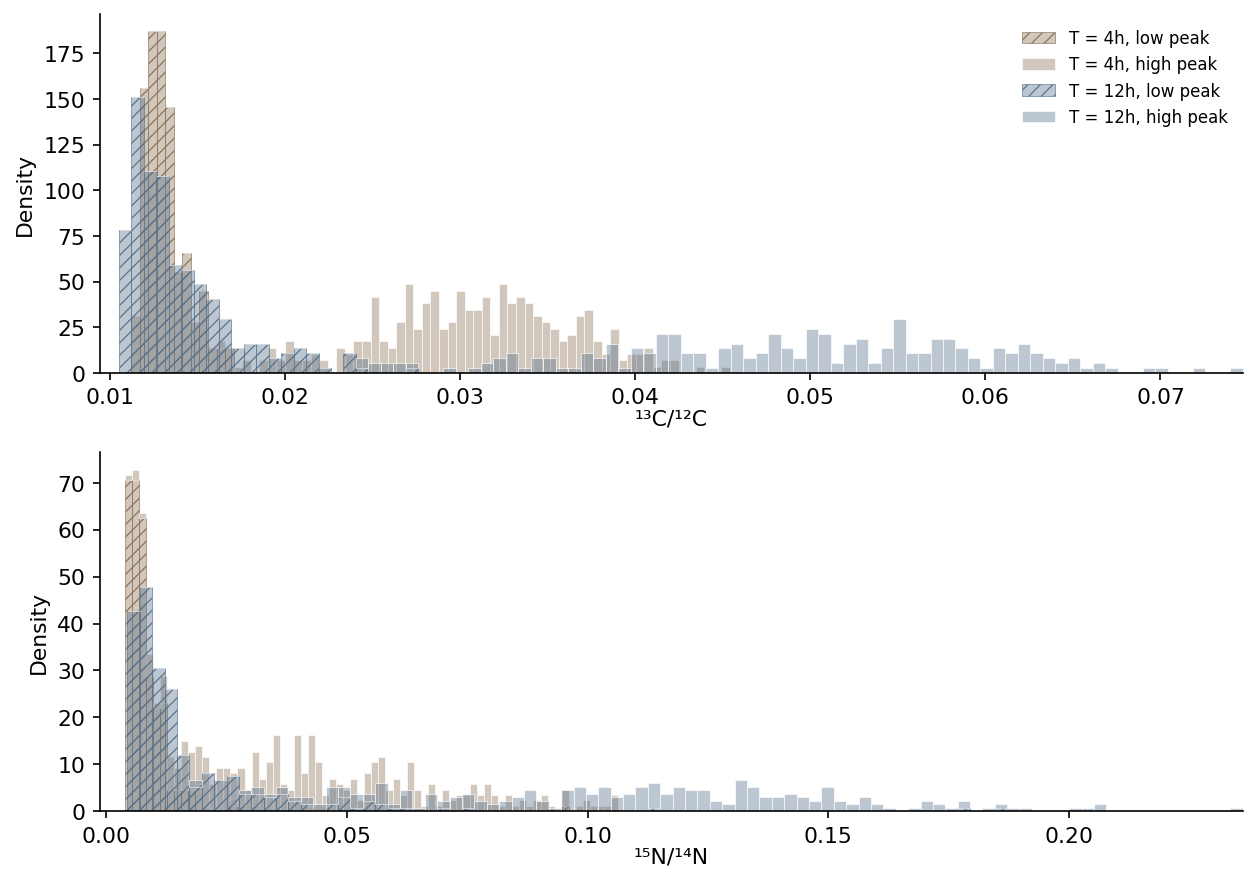

Carbon:
  Carbon low [C_low]: diff=-0.00080636, 95% CI=[-0.0013955, -0.00029761], p=0.0240
  Carbon high [C_high]: diff=-0.018252, 95% CI=[-0.020191, -0.016043], p=0.0000
Nitrogen:
  Nitrogen low [N_low]: diff=-0.0084012, 95% CI=[-0.011059, -0.0055203], p=0.0000
  Nitrogen high [N_high]: diff=-0.063435, 95% CI=[-0.070088, -0.056003], p=0.0000
FDR-corrected p-values: {'C_low': np.float64(0.024), 'C_high': np.float64(0.0), 'N_low': np.float64(0.0), 'N_high': np.float64(0.0)}


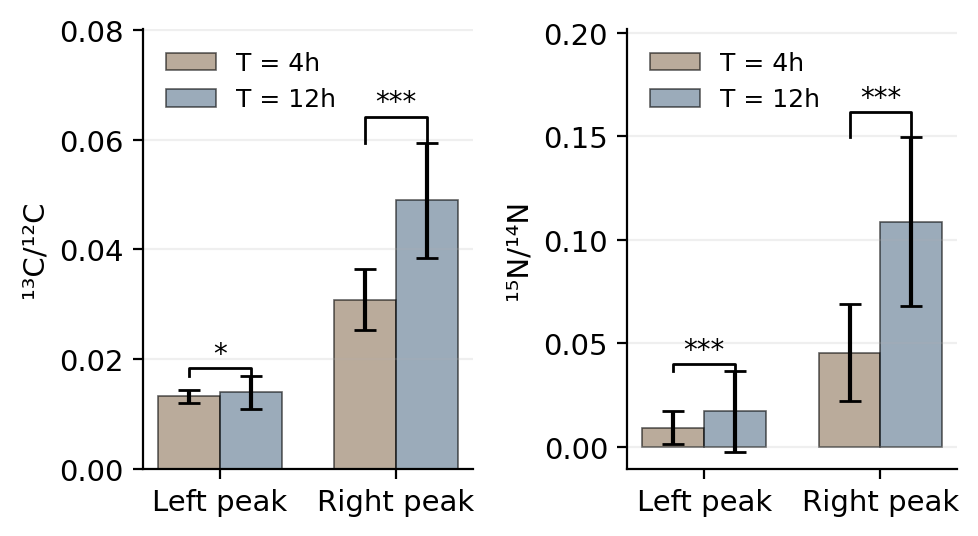

In [7]:
"""
Cluster log(C_ratio) vs log(N_ratio) into two groups for two timepoints (4h, 12h), and
check that BOTH ratios come out bimodal under the split.

Figure 1 - clustering diagnostic (3 rows x 2 cols, one column per timepoint):
  row 0: overlaid histograms of C_ratio for the two clusters
  row 1: overlaid histograms of N_ratio for the two clusters
  row 2: scatter of C_ratio vs N_ratio, colored by cluster

Figure 2 - C/N by timepoint (2 rows x 1 col, stacked):
  top:    histogram of C_ratio for 4h and 12h overlaid, one color per timepoint.
          Within each timepoint the bars are split by the GMM's two clusters
          (stacked): the low group is drawn hatched, the high group solid, so
          the total bar height is still the full timepoint histogram. No fitted
          curves are drawn.
  bottom: same, for N_ratio

Why this changed from plain k-means:
  - C_ratio and N_ratio don't have the same spread (N_ratio's range is often
    ~2-3x C_ratio's). Plain k-means on the raw log values lets whichever
    variable has more variance dominate the Euclidean distance, so the split
    mostly tracks N_ratio and C_ratio ends up smeared across both clusters
    (poor separation in the C_ratio marginal -> not bimodal). Fix: z-score
    both log-ratios (StandardScaler) before clustering so they contribute
    equally.
  - K-means also assumes round, equal-size, equal-variance clusters. Your
    data is an elongated, positively-correlated cloud (a tight low group +
    a more spread-out high group) - not what k-means is built for. A
    Gaussian Mixture Model (GMM) fits ellipses aligned with the actual
    covariance of each group and is the standard tool when you expect the
    data to be a mixture of ~2 (bimodal) populations. GMM is now the
    default; k-means is kept as an option for comparison.

Requires: numpy, pandas, matplotlib, scikit-learn, scipy, statsmodels
    pip install scikit-learn matplotlib pandas numpy scipy statsmodels
"""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.stats import norm
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.multitest import multipletests  # was missing, run_cluster_stats needs it

# ---- categorical colors (colorblind-safe adjacent pair) ----
COLOR_CLUSTER0 = "#2a78d6"  # blue   = "low" group
COLOR_CLUSTER1 = "#eb6834"  # orange = "high" group
CLUSTER_COLORS = [COLOR_CLUSTER0, COLOR_CLUSTER1]

# colors per timepoint, used only in the combined C/N-by-timepoint figure
# (that figure does NOT color by cluster, so it gets its own color map)
TIMEPOINT_COLORS = {"T4_rep2": "#2a78d6", "T12_rep2": "#eb6834"}


def cluster_log_ratios(df, method="gmm", n_clusters=2, random_state=42):
    """
    Compute log(C_ratio), log(N_ratio), standardize them, and split into
    n_clusters groups.

    method: "gmm" (default, recommended) or "kmeans".

    Clusters are relabeled so cluster 0 always has the lower mean
    (standardized logC + logN) -> "low" group, cluster 1 -> "high" group.
    This keeps colors/labels consistent across panels and datasets, since
    both GMM and k-means assign arbitrary label numbers each run.

    Returns (data, model, scaler) where data has columns
    [logC, logN, cluster].
    """
    logC = np.log(df["C_ratio"])
    logN = np.log(df["N_ratio"])
    data = pd.DataFrame({"logC": logC, "logN": logN})
    data = data.replace([np.inf, -np.inf], np.nan).dropna()
    data["C_ratio"] = df["C_ratio"]
    data["N_ratio"] = df["N_ratio"]

    scaler = StandardScaler()
    X = scaler.fit_transform(data[["logC", "logN"]])

    if method == "gmm":
        model = GaussianMixture(
            n_components=n_clusters, covariance_type="full",
            random_state=random_state, n_init=10,
        )
        labels = model.fit_predict(X)
    elif method == "kmeans":
        model = KMeans(n_clusters=n_clusters, random_state=random_state, n_init=10)
        labels = model.fit_predict(X)
    else:
        raise ValueError("method must be 'gmm' or 'kmeans'")

    # relabel by ascending mean score so 0 = low group, 1 = high group
    score = X.sum(axis=1)
    order = pd.Series(score, index=data.index).groupby(labels).mean().sort_values().index
    relabel = {old: new for new, old in enumerate(order)}
    data["cluster"] = [relabel[l] for l in labels]
    return data, model, scaler


def plot_scatter(ax, data, title):
    for cluster_id in sorted(data["cluster"].unique()):
        sub = data[data["cluster"] == cluster_id]
        ax.scatter(
            sub["C_ratio"], sub["N_ratio"],
            s=18, alpha=0.75,
            color=CLUSTER_COLORS[cluster_id],
            edgecolor="white", linewidth=0.3,
            label=f"Cluster {cluster_id}",
        )
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("¹³C/¹²C")
    ax.set_ylabel("¹⁵N/¹⁴N")
    ax.set_title(title)
    ax.legend(frameon=False, fontsize=8)


def plot_hist(ax, data, title, column, bins=70):
    for cluster_id in sorted(data["cluster"].unique()):
        sub = data[data["cluster"] == cluster_id]
        ax.hist(
            sub[column], bins=bins, alpha=0.55,
            color=CLUSTER_COLORS[cluster_id],
            edgecolor="white", linewidth=0.3,
            label=f"Cluster {cluster_id}",
        )
    xlabel = "¹³C/¹²C" if column == "C_ratio" else "¹⁵N/¹⁴N"
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Count")
    ax.set_title(title)
    ax.legend(frameon=False, fontsize=8)


CLUSTER_NAMES = ["low", "high"]
CLUSTER_HATCHES = ["////", None]  # cluster 0 (low peak) hatched, cluster 1 (high peak) solid
plt.rcParams["hatch.linewidth"] = 0.6


def plot_timepoint_histogram(ax, datasets, clustered, column, xlabel, show_legend=False):
    """
    Overlay histograms of `column` for every timepoint in `datasets`,
    colored by TIMEPOINT. Within each timepoint the bars are split by its
    two GMM clusters, stacked on top of each other with shared bin edges:
    low peak = hatched, high peak = solid fill (same timepoint color). The
    stack is normalized as a whole (density=True + stacked=True), so the
    outline of each timepoint is the same as the unsplit histogram.

    `clustered` is {name: data} as returned by cluster_log_ratios(df)[0],
    precomputed once per timepoint so it can be shared between the C and N
    panels.
    """
    bins = [70, 90]
    color4 = (0.55, 0.45, 0.35, 0.4)    # muted warm grey (taupe)  - fill
    color12 = (0.35, 0.45, 0.55, 0.4)   # muted cool grey (slate blue) - fill
    colors = [color4, color12]

    legend_handles = []
    for i, name in enumerate(datasets.keys()):
        data = clustered[name]
        vals_all = data[column]
        edges = np.histogram_bin_edges(vals_all, bins=bins[i])  # same bins for both clusters

        fill = colors[i]
        line = (*fill[:3], 1.0)  # opaque version of the timepoint color, for the hatch lines

        cluster_ids = sorted(data["cluster"].unique())
        vals_by_cluster = [data.loc[data["cluster"] == c, column] for c in cluster_ids]

        _, _, patch_groups = ax.hist(
            vals_by_cluster, bins=edges, density=True, stacked=True,
            color=[fill] * len(cluster_ids),
        )
        # matplotlib returns a single BarContainer (not a list) if there is only one cluster
        if len(cluster_ids) == 1:
            patch_groups = [patch_groups]

        for cluster_id, patches in zip(cluster_ids, patch_groups):
            hatch = CLUSTER_HATCHES[cluster_id]
            for p in patches:
                if hatch:
                    # hatch lines are drawn in the edge color
                    p.set_hatch(hatch)
                    p.set_edgecolor(line)
                    p.set_linewidth(0.3)
                else:
                    p.set_edgecolor("white")
                    p.set_linewidth(0.3)

        for cluster_id in cluster_ids:
            legend_handles.append(Patch(
                facecolor=fill,
                edgecolor=line if CLUSTER_HATCHES[cluster_id] else "white",
                hatch=CLUSTER_HATCHES[cluster_id], linewidth=0.3,
                label=f"{name}, {CLUSTER_NAMES[cluster_id]} peak",
            ))

    ax.set_xlabel(xlabel, labelpad=0.55)
    ax.set_ylabel("Density")
    ax.set_xlim(min(datasets['T = 4h'][column])-0.00002/min(datasets['T = 4h'][column]),
                max(datasets['T = 12h'][column]))
    if show_legend:
        ax.legend(handles=legend_handles, frameon=False, fontsize=8)


def plot_c_n_by_timepoint(datasets, method="gmm", outpath="c_n_by_timepoint.png"):
    """
    2-panel figure, stacked (2 rows x 1 col): top = C_ratio histograms for
    every timepoint in `datasets`, bottom = N_ratio histograms. One color per
    timepoint; within a timepoint the low/high GMM clusters are shown as
    hatched/solid stacked bars (see plot_timepoint_histogram).
    """
    # cluster each timepoint once, reused for both the C and N panels
    clustered = {name: cluster_log_ratios(df, method=method, n_clusters=2)[0]
                 for name, df in datasets.items()}

    fig, axes = plt.subplots(2, 1, figsize=(8.5, 6))
    plot_timepoint_histogram(axes[0], datasets, clustered, "C_ratio", "¹³C/¹²C", show_legend=True)
    plot_timepoint_histogram(axes[1], datasets, clustered, "N_ratio", "¹⁵N/¹⁴N")
    plt.tight_layout()
    plt.savefig(outpath, dpi=200)

    plt.show()

def cluster_gaussian_stats(data, column):
    """
    Gaussian fit (mean, std) of `column` for each cluster in an already-
    clustered `data` frame (as returned by cluster_log_ratios(df)[0]).
    Returns (means, stds), each a length-2 array ordered [low, high] --
    the same low/high ordering cluster_log_ratios already guarantees.
    """
    means = np.zeros(2)
    stds = np.zeros(2)
    for cluster_id in (0, 1):
        sub = data.loc[data["cluster"] == cluster_id, column]
        means[cluster_id], stds[cluster_id] = norm.fit(sub)
    return means, stds


def bootstrap_cluster_means(df, method="gmm", n_boot=500, random_state=0):
    """
    Resample `df` with replacement, redo the SAME joint (standardized
    logC, logN) GMM/k-means split used throughout this script
    (cluster_log_ratios), and record the resulting low/high cluster means
    of C_ratio and N_ratio. This captures clustering-fit uncertainty, not
    just point-assignment noise -- a bad bootstrap draw can flip which
    points land in which cluster entirely.

    Returns a dict of length-n_boot arrays: {"C_low", "C_high", "N_low",
    "N_high"} (NaN for any bootstrap draw where the fit failed or a
    cluster came out empty).
    """
    rng = np.random.default_rng(random_state)
    n = len(df)
    out = {k: np.full(n_boot, np.nan) for k in ("C_low", "C_high", "N_low", "N_high")}
    n_failed = 0
    for i in range(n_boot):
        idx = rng.integers(0, n, size=n)
        sample = df.iloc[idx].reset_index(drop=True)
        try:
            data, _, _ = cluster_log_ratios(sample, method=method, n_clusters=2, random_state=i)
            for cluster_id, tag in ((0, "low"), (1, "high")):
                sub = data.loc[data["cluster"] == cluster_id]
                if len(sub) > 1:
                    out[f"C_{tag}"][i] = sub["C_ratio"].mean()
                    out[f"N_{tag}"][i] = sub["N_ratio"].mean()
        except Exception:
            n_failed += 1
    if n_failed:
        print(f"  ({n_failed}/{n_boot} bootstrap fits failed/degenerate)")
    return out


def bootstrap_diff_pvalue(boot_a, boot_b, key, label=None, n_draws=2000, random_state=0):
    """
    Two-sided bootstrap p-value for whether the `key` cluster mean
    (e.g. "C_low") differs between two bootstrap distributions
    (from bootstrap_cluster_means). Draws random pairs from each
    distribution and reports the fraction of differences that cross zero.
    """
    rng = np.random.default_rng(random_state)
    a = boot_a[key]
    a = a[~np.isnan(a)]
    b = boot_b[key]
    b = b[~np.isnan(b)]
    diff = rng.choice(a, n_draws, replace=True) - rng.choice(b, n_draws, replace=True)
    p = min(2 * min((diff > 0).mean(), (diff < 0).mean()), 1.0)
    if label is not None:
        obs_diff = np.nanmean(a) - np.nanmean(b)
        ci_lo, ci_hi = np.percentile(diff, [2.5, 97.5])
        print(f"  {label} [{key}]: diff={obs_diff:.5g}, 95% CI=[{ci_lo:.5g}, {ci_hi:.5g}], p={p:.4f}")
    return p


def run_cluster_stats(datasets, method="gmm", n_boot=500, alpha=0.05):
    """
    Bootstrap-test each cluster's mean (C_low, C_high, N_low, N_high)
    between the two timepoints in `datasets`, then apply Benjamini-Hochberg
    FDR correction across all four tests. Returns a dict of FDR-corrected
    p-values keyed "C_low", "C_high", "N_low", "N_high".
    """
    names = list(datasets.keys())
    if len(names) != 2:
        raise ValueError("run_cluster_stats expects exactly two timepoints")
    name_a, name_b = names

    boot = {
        name: bootstrap_cluster_means(df, method=method, n_boot=n_boot, random_state=42 + i)
        for i, (name, df) in enumerate(datasets.items())
    }

    print("Carbon:")
    p_C_low = bootstrap_diff_pvalue(boot[name_a], boot[name_b], "C_low", label="Carbon low")
    p_C_high = bootstrap_diff_pvalue(boot[name_a], boot[name_b], "C_high", label="Carbon high")
    print("Nitrogen:")
    p_N_low = bootstrap_diff_pvalue(boot[name_a], boot[name_b], "N_low", label="Nitrogen low")
    p_N_high = bootstrap_diff_pvalue(boot[name_a], boot[name_b], "N_high", label="Nitrogen high")

    keys = ["C_low", "C_high", "N_low", "N_high"]
    raw_pvals = [p_C_low, p_C_high, p_N_low, p_N_high]
    _, pvals_corrected, _, _ = multipletests(raw_pvals, alpha=alpha, method="fdr_bh")
    print("FDR-corrected p-values:", dict(zip(keys, np.round(pvals_corrected, 4))))
    return dict(zip(keys, pvals_corrected))


def p_to_star(p):
    if p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    else:
        return "ns"


def add_sig_bracket(ax, x1, x2, y_top, p, gap=0.08):
    """Draw a significance bracket + star/ns label just above y_top."""
    y_line = y_top * (1 + gap)
    ax.plot([x1, x1, x2, x2], [y_top, y_line, y_line, y_top], lw=1, color="black")
    ax.text((x1 + x2) / 2, y_line, p_to_star(p), ha="center", va="bottom", fontsize=10)


def plot_cluster_stats_barplot(datasets, clustered, pvals, outpath="cluster_stats_barplot.png"):
    """
    1x2 bar plot of low/high cluster means (+- std) for C_ratio and
    N_ratio, comparing the two timepoints in `datasets`. Cluster stats come
    from `clustered` (the same joint GMM split used in the other figures);
    `pvals` is the dict returned by run_cluster_stats, used to draw
    significance brackets between the two timepoints for each cluster.
    """
    names = list(datasets.keys())
    name_a, name_b = names
    color4 = (0.55, 0.45, 0.35, 0.4)   # muted warm grey (taupe)
    color12 = (0.35, 0.45, 0.55, 0.4)   # muted cool grey (slate blue)
    color_a = color4
    color_b = color12

    means_C_a, stds_C_a = cluster_gaussian_stats(clustered[name_a], "C_ratio")
    means_C_b, stds_C_b = cluster_gaussian_stats(clustered[name_b], "C_ratio")
    means_N_a, stds_N_a = cluster_gaussian_stats(clustered[name_a], "N_ratio")
    means_N_b, stds_N_b = cluster_gaussian_stats(clustered[name_b], "N_ratio")

    x = np.arange(2)  # [low, high]
    width = 0.35
    fig, axes = plt.subplots(1, 2, figsize=(5, 2.8), dpi=200)

    def _panel(ax, means_a, stds_a, means_b, stds_b, ylabel, title, p_low, p_high):
        ax.bar(x - width / 2, means_a, width, yerr=stds_a, capsize=4, label=name_a,
               color=color_a, alpha=0.6, edgecolor="black", linewidth=0.6)
        ax.bar(x + width / 2, means_b, width, yerr=stds_b, capsize=4, label=name_b,
               color=color_b, alpha=0.6, edgecolor="black", linewidth=0.6)
        ax.set_xticks(x)
        ax.set_xticklabels(["Left peak", "Right peak"])
        ax.set_ylabel(ylabel)
        #ax.set_title(title)
        ax.legend(frameon=False, fontsize=9)
        ax.grid(axis="y", alpha=0.2)

        top_low = max(means_a[0] + stds_a[0], means_b[0] + stds_b[0])
        top_high = max(means_a[1] + stds_a[1], means_b[1] + stds_b[1])
        add_sig_bracket(ax, 0 - width / 2, 0 + width / 2, top_low, p_low)
        add_sig_bracket(ax, 1 - width / 2, 1 + width / 2, top_high, p_high)
        ax.set_ylim(top=max(top_low, top_high) * 1.35)

    _panel(axes[0], means_C_a, stds_C_a, means_C_b, stds_C_b,
           "¹³C/¹²C", "Carbon cluster means", pvals["C_low"], pvals["C_high"])
    _panel(axes[1], means_N_a, stds_N_a, means_N_b, stds_N_b,
           "¹⁵N/¹⁴N", "Nitrogen cluster means", pvals["N_low"], pvals["N_high"])

    plt.tight_layout()
    plt.savefig(outpath, dpi=200)
    plt.show()


def main(t4_rep2, t12_rep2, method="gmm", n_boot=100):
    datasets = {"T = 4h": t4_rep2, "T = 12h": t12_rep2}

    # --- Figure 1: clustering diagnostic, one column per timepoint ---
    #fig, axes = plt.subplots(3, 2, figsize=(11, 11))
    #for col_idx, (name, df) in enumerate(datasets.items()):
    #    data, model, scaler = cluster_log_ratios(df, method=method, n_clusters=2)
    #    plot_hist(axes[0, col_idx], data, f"{name}: C_ratio by cluster", column="C_ratio")
    #    plot_hist(axes[1, col_idx], data, f"{name}: N_ratio by cluster", column="N_ratio")
    #    plot_scatter(axes[2, col_idx], data, f"{name}")
    #plt.tight_layout()
    #plt.savefig("clusters_figure.png", dpi=200)
    #plt.show()
    clustered = {name: cluster_log_ratios(df, method=method, n_clusters=2)[0]
                 for name, df in datasets.items()}

    # --- Figure 2: C and N histograms across timepoints, bars split by cluster ---
    plot_c_n_by_timepoint(datasets, method=method, outpath="c_n_by_timepoint.png")

    # --- Figure 3: cluster means bar plot, 4h vs 12h, with bootstrap significance ---
    pvals = run_cluster_stats(datasets, method=method, n_boot=n_boot)
    plot_cluster_stats_barplot(datasets, clustered, pvals, outpath="cluster_stats_barplot.png")


if __name__ == "__main__":
    # replace with your actual dataframes, e.g. loaded via pd.read_csv(...)
    blank = load(("0h", "blank"))
    t4_rep2 = load(("4h", "rep2"))
    t12_rep2 = load(("12h", "rep2"))

    # thresholds from the blank distribution
    c_thresh = blank["C_ratio"].mean() - blank["C_ratio"].std()
    n_thresh = blank["N_ratio"].mean() - blank["N_ratio"].std()

    def filter_below_blank(df, c_thresh, n_thresh):
        return df[(df["C_ratio"] >= c_thresh) & (df["N_ratio"] >= n_thresh)]

    t4_rep2_filt = filter_below_blank(t4_rep2, c_thresh, n_thresh)
    t12_rep2_filt = filter_below_blank(t12_rep2, c_thresh, n_thresh)

    def save_filtered(df, timepoint, replicate):
        filename = f"experiments/new_data/replicates/{timepoint}_{replicate}_filtered.csv"
        df.to_csv(filename, index=False)
        print(f"Saved {filename} ({len(df)} rows)")

    save_filtered(t4_rep2_filt, "4h", "rep2")
    save_filtered(t12_rep2_filt, "12h", "rep2")

    main(t4_rep2_filt, t12_rep2_filt, method="gmm")

Saved experiments/new_data/replicates/4h_rep2_filtered.csv (591 rows)
Saved experiments/new_data/replicates/12h_rep2_filtered.csv (520 rows)
T = 4h C_ratio low (truncated @ 0.011202, log): peak/mean=0.012795, sd=0.00115
T = 4h C_ratio high: peak/mean=0.0308, sd=0.00555
T = 12h C_ratio low (truncated @ 0.010495, log): peak/mean=0.010495, sd=0.00296
T = 12h C_ratio high: peak/mean=0.048972, sd=0.0105
T = 4h N_ratio low (truncated @ 0.0038678, log): peak/mean=0.0038678, sd=0.00583
T = 4h N_ratio high: peak/mean=0.045334, sd=0.0234
T = 12h N_ratio low (truncated @ 0.0044237, log): peak/mean=0.0044237, sd=0.0175
T = 12h N_ratio high: peak/mean=0.10875, sd=0.0409


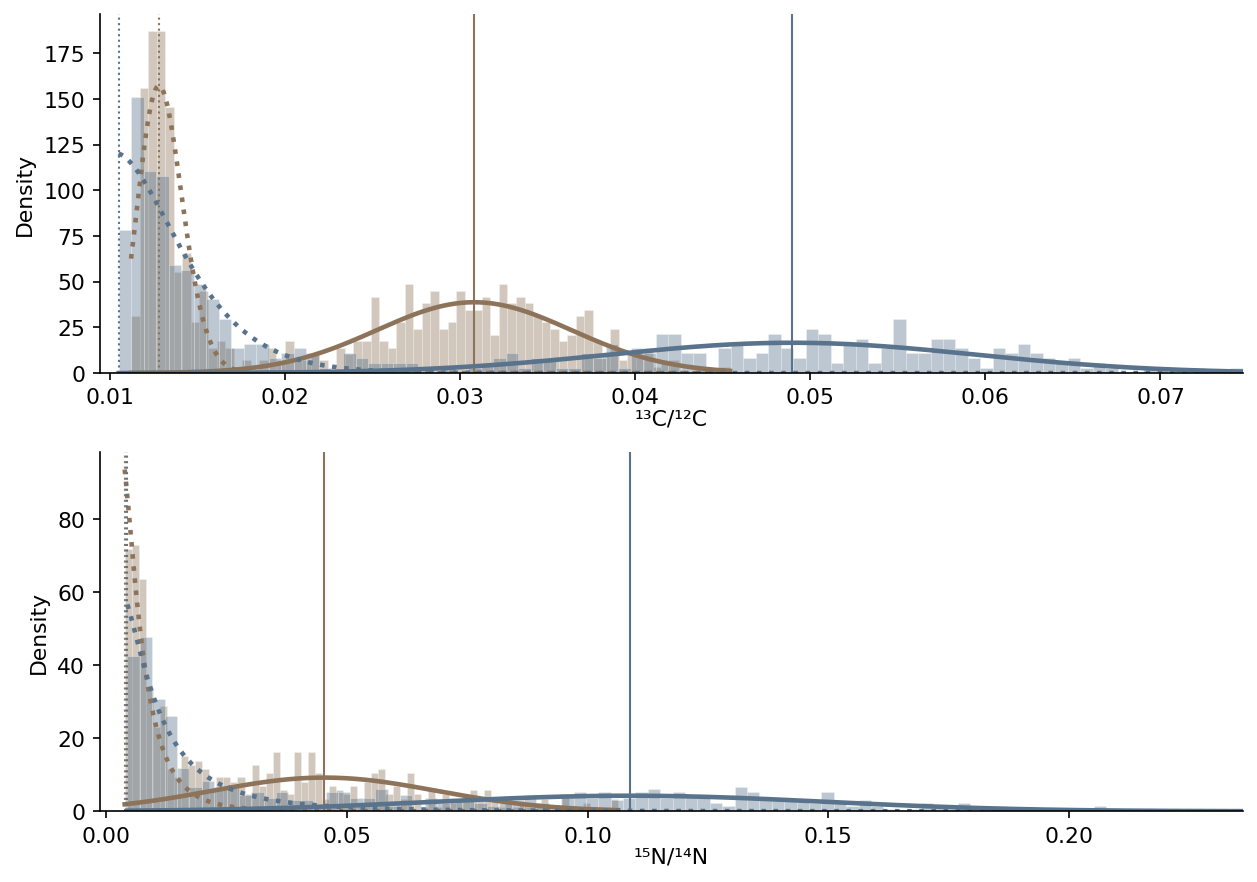

Carbon:
  Carbon low [C_low]: diff=0.0020117, 95% CI=[0.0011945, 0.0024165], p=0.0000
  Carbon high [C_high]: diff=-0.018252, 95% CI=[-0.020191, -0.016043], p=0.0000
Nitrogen:
  Nitrogen low [N_low]: diff=-0.00025643, 95% CI=[-0.0016383, 0.0011446], p=0.5530
  Nitrogen high [N_high]: diff=-0.063435, 95% CI=[-0.070088, -0.056003], p=0.0000
FDR-corrected p-values: {'C_low': np.float64(0.0), 'C_high': np.float64(0.0), 'N_low': np.float64(0.553), 'N_high': np.float64(0.0)}


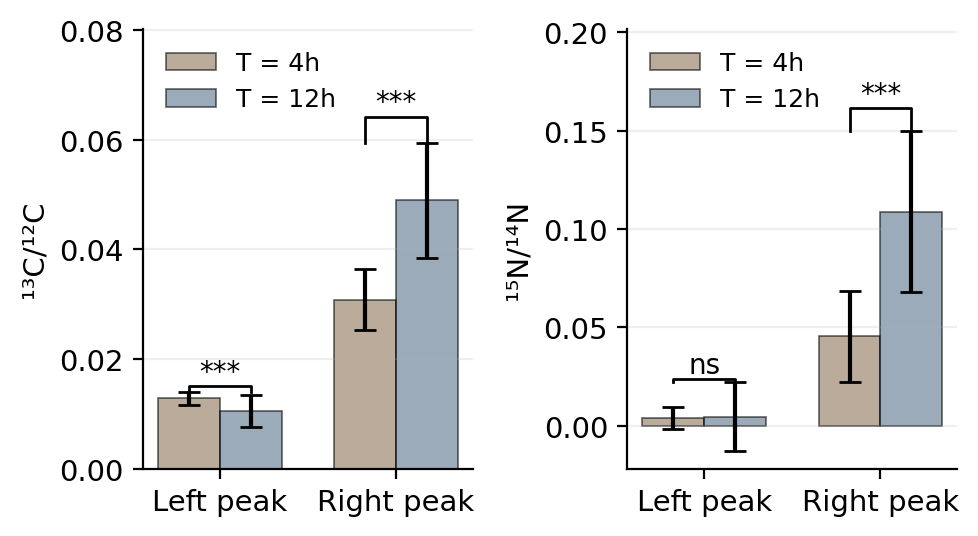

In [7]:
"""
Cluster log(C_ratio) vs log(N_ratio) into two groups for two timepoints (4h, 12h), and
check that BOTH ratios come out bimodal under the split.

Figure 1 - clustering diagnostic (3 rows x 2 cols, one column per timepoint):
  row 0: overlaid histograms of C_ratio for the two clusters
  row 1: overlaid histograms of N_ratio for the two clusters
  row 2: scatter of C_ratio vs N_ratio, colored by cluster

Figure 2 - C/N by timepoint (2 rows x 1 col, stacked):
  top:    histogram of C_ratio for 4h and 12h overlaid, one color per timepoint
          (bars are NOT split by cluster). Within each timepoint, the GMM's
          two clusters (low/high group) each get their own fitted curve
          (same color as the timepoint, different linestyle):
            - LEFT peak (cluster 0, "low"): Gaussian TRUNCATED from below at
              the minimum ratio observed for that timepoint (MLE fit).
            - RIGHT peak (cluster 1, "high"): plain Gaussian.
  bottom: same, for N_ratio

Figure 3 - bar plot of low/high cluster means (+- std), 4h vs 12h, with
bootstrap + BH-FDR significance brackets.

Why GMM on standardized log-ratios (instead of plain k-means):
  - C_ratio and N_ratio don't have the same spread. Plain k-means on the raw
    log values lets the higher-variance variable dominate the distance.
    Fix: z-score both log-ratios before clustering.
  - K-means assumes round, equal-variance clusters. A GMM with full
    covariance fits ellipses aligned with each group's actual covariance.

Why a truncated Gaussian for the left peak:
  - The left peak sits against the lower edge of the data (the blank-based
    filter / detection limit), so it is cut off on its left side. A plain
    Gaussian fit to a cut-off peak is biased (mean too high, std too
    small). The truncated fit estimates the underlying Gaussian (mu, sigma)
    given that nothing below `lower` can be observed.
  - The left peak is right-skewed, so by default the truncated Gaussian is
    fit on log(ratio) (LEFT_PEAK_SPACE = "log"), consistent with the
    log-space clustering. A linear-space fit tries to absorb the skew by
    pushing mu below the cutoff, giving a monotone decaying curve.
  - The vertical line / bar for the left peak is the PEAK (mode) of the
    fitted distribution. If the peak truly lies at or below the cutoff
    (counts just decay from the minimum), the mode is reported as `lower`.

Requires: numpy, pandas, matplotlib, scikit-learn, scipy, statsmodels
    pip install scikit-learn matplotlib pandas numpy scipy statsmodels
"""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.optimize import minimize
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.multitest import multipletests

# ---- categorical colors (colorblind-safe adjacent pair) ----
COLOR_CLUSTER0 = "#2a78d6"  # blue   = "low" group
COLOR_CLUSTER1 = "#eb6834"  # orange = "high" group
CLUSTER_COLORS = [COLOR_CLUSTER0, COLOR_CLUSTER1]

# colors per timepoint, used only in the combined C/N-by-timepoint figure
TIMEPOINT_COLORS = {"T4_rep2": "#2a78d6", "T12_rep2": "#eb6834"}

# muted fills shared by Figure 2 and Figure 3: [4h, 12h]
COLOR_4H = (0.55, 0.45, 0.35, 0.4)    # muted warm grey (taupe)
COLOR_12H = (0.35, 0.45, 0.55, 0.4)   # muted cool grey (slate blue)
TP_FILL_COLORS = [COLOR_4H, COLOR_12H]

CLUSTER_LINESTYLES = [":", "-"]  # cluster 0 (low group) dotted, cluster 1 (high group) solid
CLUSTER_NAMES = ["low", "high"]

# If True, the left peak (cluster 0) is fit with a Gaussian truncated at the
# minimum observed ratio, both in Figure 2 and in the Figure 3 bar plot.
TRUNCATE_LEFT_PEAK = True

# Space in which the left-peak truncated Gaussian is fit:
#   "log"    -> truncated Gaussian on log(ratio) (= truncated log-normal).
#               Handles the right skew of the low peak and matches the
#               log-space GMM clustering. Recommended.
#   "linear" -> truncated Gaussian on the raw ratio.
LEFT_PEAK_SPACE = "log"


# =============================================================================
# Truncated Gaussian (lower bound only)
# =============================================================================
def fit_truncnorm_lower(x, lower):
    """
    Maximum-likelihood fit of a Gaussian truncated from below at `lower`
    (no upper bound). Returns (mu, sigma) of the UNDERLYING (untruncated)
    Gaussian.

        pdf(x) = N(x; mu, sigma) / (1 - Phi((lower - mu) / sigma)),  x >= lower

    mu is bounded to [lower - 3*sd, max(x)]. Without that bound, a peak whose
    mode lies at/below the cutoff (counts just decay from the minimum) makes
    the MLE run away to mu -> -inf, sigma -> inf, and the pdf becomes 0/0 = NaN
    (the curve disappears from the plot).
    """
    x = np.asarray(x, float)
    x = x[x >= lower]
    sd = x.std()

    def nll(p):
        mu, s = p[0], np.exp(p[1])  # optimize log-sigma so sigma stays > 0
        return -(norm.logpdf(x, mu, s).sum() - len(x) * norm.logsf(lower, mu, s))

    bounds = [(lower - 3 * sd, x.max()), (np.log(sd / 50), np.log(sd * 5))]
    best = None
    for mu0 in (np.median(x), lower, x.mean()):  # multi-start, keep best
        res = minimize(nll, [mu0, np.log(sd)], method="L-BFGS-B", bounds=bounds)
        if best is None or res.fun < best.fun:
            best = res
    return best.x[0], np.exp(best.x[1])


def _truncnorm_logpdf(z, mu, sigma, lower):
    """Stable log-pdf of the lower-truncated Gaussian (computed in log space)."""
    return norm.logpdf(z, mu, sigma) - norm.logsf(lower, mu, sigma)


class LeftPeakFit:
    """
    Truncated fit of the left peak, in linear or log space.
    Attributes: mu, sigma (underlying Gaussian, in the fit space),
    lower, space, peak (mode of the fitted distribution, >= lower),
    mean, sd (moments of the fitted truncated distribution, in ratio units).
    """

    def __init__(self, vals, lower, space=LEFT_PEAK_SPACE):
        vals = np.asarray(vals, float)
        self.lower, self.space = lower, space
        if space == "log":
            self.mu, self.sigma = fit_truncnorm_lower(np.log(vals), np.log(lower))
            self.peak = max(np.exp(self.mu - self.sigma ** 2), lower)  # log-normal mode
            upper = np.exp(self.mu + 8 * self.sigma)
        elif space == "linear":
            self.mu, self.sigma = fit_truncnorm_lower(vals, lower)
            self.peak = max(self.mu, lower)
            upper = self.mu + 8 * self.sigma
        else:
            raise ValueError("space must be 'log' or 'linear'")
        # moments of the fitted truncated distribution (numerical)
        grid = np.linspace(lower, max(upper, vals.max()), 20000)
        p = self.pdf(grid)
        p /= np.trapezoid(p, grid)
        self.mean = np.trapezoid(grid * p, grid)
        self.sd = np.sqrt(np.trapezoid((grid - self.mean) ** 2 * p, grid))

    def pdf(self, xs):
        xs = np.asarray(xs, float)
        xc = np.maximum(xs, self.lower)
        if self.space == "log":
            lp = _truncnorm_logpdf(np.log(xc), self.mu, self.sigma, np.log(self.lower)) - np.log(xc)
        else:
            lp = _truncnorm_logpdf(xc, self.mu, self.sigma, self.lower)
        return np.where(xs >= self.lower, np.exp(lp), 0.0)


def fit_cluster_curve(sub_vals, cluster_id, lower, truncate_low=TRUNCATE_LEFT_PEAK):
    """
    Fit the curve used for one cluster.
      Left peak (cluster 0) -> truncated fit with lower bound `lower`
                               (see LEFT_PEAK_SPACE).
      Right peak            -> plain Gaussian.
    Returns (location, spread, pdf_func, is_truncated), where location is
    the peak position (mode) for the left peak and the mean for the right
    peak, and spread is the SD of the fitted distribution.
    """
    if cluster_id == 0 and truncate_low:
        fit = LeftPeakFit(sub_vals, lower)
        return fit.peak, fit.sd, fit.pdf, True
    mu, sigma = norm.fit(sub_vals)
    return mu, sigma, (lambda xs: norm.pdf(xs, mu, sigma)), False


# =============================================================================
# Clustering
# =============================================================================
def cluster_log_ratios(df, method="gmm", n_clusters=2, random_state=42):
    """
    Compute log(C_ratio), log(N_ratio), standardize them, and split into
    n_clusters groups.

    method: "gmm" (default, recommended) or "kmeans".

    Clusters are relabeled so cluster 0 always has the lower mean
    (standardized logC + logN) -> "low" group, cluster 1 -> "high" group.

    Returns (data, model, scaler) where data has columns
    [logC, logN, C_ratio, N_ratio, cluster].
    """
    logC = np.log(df["C_ratio"])
    logN = np.log(df["N_ratio"])
    data = pd.DataFrame({"logC": logC, "logN": logN})
    data = data.replace([np.inf, -np.inf], np.nan).dropna()
    data["C_ratio"] = df["C_ratio"]
    data["N_ratio"] = df["N_ratio"]

    scaler = StandardScaler()
    X = scaler.fit_transform(data[["logC", "logN"]])

    if method == "gmm":
        model = GaussianMixture(
            n_components=n_clusters, covariance_type="full",
            random_state=random_state, n_init=10,
        )
        labels = model.fit_predict(X)
    elif method == "kmeans":
        model = KMeans(n_clusters=n_clusters, random_state=random_state, n_init=10)
        labels = model.fit_predict(X)
    else:
        raise ValueError("method must be 'gmm' or 'kmeans'")

    # relabel by ascending mean score so 0 = low group, 1 = high group
    score = X.sum(axis=1)
    order = pd.Series(score, index=data.index).groupby(labels).mean().sort_values().index
    relabel = {old: new for new, old in enumerate(order)}
    data["cluster"] = [relabel[l] for l in labels]
    return data, model, scaler


# =============================================================================
# Figure 1 helpers (clustering diagnostic)
# =============================================================================
def plot_scatter(ax, data, title):
    for cluster_id in sorted(data["cluster"].unique()):
        sub = data[data["cluster"] == cluster_id]
        ax.scatter(
            sub["C_ratio"], sub["N_ratio"],
            s=18, alpha=0.75,
            color=CLUSTER_COLORS[cluster_id],
            edgecolor="white", linewidth=0.3,
            label=f"Cluster {cluster_id}",
        )
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("¹³C/¹²C")
    ax.set_ylabel("¹⁵N/¹⁴N")
    ax.set_title(title)
    ax.legend(frameon=False, fontsize=8)


def plot_hist(ax, data, title, column, bins=70):
    for cluster_id in sorted(data["cluster"].unique()):
        sub = data[data["cluster"] == cluster_id]
        ax.hist(
            sub[column], bins=bins, alpha=0.55,
            color=CLUSTER_COLORS[cluster_id],
            edgecolor="white", linewidth=0.3,
            label=f"Cluster {cluster_id}",
        )
    xlabel = "¹³C/¹²C" if column == "C_ratio" else "¹⁵N/¹⁴N"
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Count")
    ax.set_title(title)
    ax.legend(frameon=False, fontsize=8)


# =============================================================================
# Figure 2 (C/N by timepoint, per-cluster fits)
# =============================================================================
def plot_timepoint_histogram(ax, datasets, clustered, column, xlabel, bins=(70, 90)):
    """
    Overlay histograms of `column` for every timepoint in `datasets`,
    one color per timepoint. On top, draw one fitted curve per GMM cluster:
    left peak = Gaussian truncated at the timepoint's minimum observed ratio,
    right peak = plain Gaussian. Each curve is weighted by its cluster's
    share of points so the two curves sum ~ to the combined density.
    """
    names = list(datasets.keys())
    for i, name in enumerate(names):
        color = TP_FILL_COLORS[i % len(TP_FILL_COLORS)]
        data = clustered[name]
        vals_all = data[column]
        lower = vals_all.min()  # minimum ratio observed for this timepoint

        ax.hist(
            vals_all, bins=bins[i % len(bins)], density=True, alpha=0.4,
            color=color, edgecolor="white", linewidth=0.3, label=name,
        )

        xs = np.linspace(lower, vals_all.max(), 400)
        for cluster_id in sorted(data["cluster"].unique()):
            sub_vals = data.loc[data["cluster"] == cluster_id, column]
            if len(sub_vals) < 2:
                continue
            weight = len(sub_vals) / len(vals_all)

            loc, spread, pdf, truncated = fit_cluster_curve(sub_vals, cluster_id, lower)
            tag = f" (truncated @ {lower:.5g}, {LEFT_PEAK_SPACE})" if truncated else ""
            print(f"{name} {column} {CLUSTER_NAMES[cluster_id]}{tag}: "
                  f"peak/mean={loc:.5g}, sd={spread:.3g}")

            ax.plot(xs, weight * pdf(xs), color=color,
                    linestyle=CLUSTER_LINESTYLES[cluster_id], linewidth=2.2, alpha=1)
            ax.axvline(loc, color=color,
                       linestyle=CLUSTER_LINESTYLES[cluster_id], linewidth=1, alpha=1)

    ax.set_xlabel(xlabel, labelpad=0.55)
    ax.set_ylabel("Density")
    first, last = names[0], names[-1]
    ax.set_xlim(min(datasets[first][column]) - 0.00002 / min(datasets[first][column]),
                max(datasets[last][column]))


def plot_c_n_by_timepoint(datasets, clustered, outpath="c_n_by_timepoint.png"):
    """2-panel figure, stacked: top = C_ratio, bottom = N_ratio."""
    fig, axes = plt.subplots(2, 1, figsize=(8.5, 6))
    plot_timepoint_histogram(axes[0], datasets, clustered, "C_ratio", "¹³C/¹²C")
    plot_timepoint_histogram(axes[1], datasets, clustered, "N_ratio", "¹⁵N/¹⁴N")
    plt.tight_layout()
    plt.savefig(outpath, dpi=200)
    plt.show()


# =============================================================================
# Cluster statistics + bootstrap test
# =============================================================================
def cluster_gaussian_stats(data, column, truncate_low=TRUNCATE_LEFT_PEAK):
    """
    (location, sd) of `column` for each cluster, ordered [low, high].
    Left peak: peak position (mode) and SD of the truncated fit (lower
    bound = min observed ratio) if truncate_low; right peak: Gaussian mean/sd.
    """
    means, stds = np.zeros(2), np.zeros(2)
    lower = data[column].min()
    for cluster_id in (0, 1):
        sub = data.loc[data["cluster"] == cluster_id, column]
        loc, spread, _, _ = fit_cluster_curve(sub, cluster_id, lower, truncate_low=truncate_low)
        means[cluster_id], stds[cluster_id] = loc, spread
    return means, stds


def bootstrap_cluster_means(df, method="gmm", n_boot=500, random_state=0,
                            truncate_low=TRUNCATE_LEFT_PEAK):
    """
    Resample `df` with replacement, redo the same GMM/k-means split and
    re-fit each cluster (truncated fit for the left peak, plain
    Gaussian for the right peak), recording the fitted location (left:
    peak/mode, right: mean) for C and N.
    This way the test compares the same quantity plotted in Figure 3.

    Returns {"C_low", "C_high", "N_low", "N_high"} -> length-n_boot arrays
    (NaN where the fit failed or a cluster was empty).
    """
    rng = np.random.default_rng(random_state)
    n = len(df)
    out = {k: np.full(n_boot, np.nan) for k in ("C_low", "C_high", "N_low", "N_high")}
    n_failed = 0
    for i in range(n_boot):
        idx = rng.integers(0, n, size=n)
        sample = df.iloc[idx].reset_index(drop=True)
        try:
            data, _, _ = cluster_log_ratios(sample, method=method, n_clusters=2, random_state=i)
            for col, prefix in (("C_ratio", "C"), ("N_ratio", "N")):
                lower = data[col].min()
                for cluster_id, tag in ((0, "low"), (1, "high")):
                    sub = data.loc[data["cluster"] == cluster_id, col]
                    if len(sub) > 1:
                        loc, _, _, _ = fit_cluster_curve(sub, cluster_id, lower,
                                                         truncate_low=truncate_low)
                        out[f"{prefix}_{tag}"][i] = loc
        except Exception:
            n_failed += 1
    if n_failed:
        print(f"  ({n_failed}/{n_boot} bootstrap fits failed/degenerate)")
    return out


def bootstrap_diff_pvalue(boot_a, boot_b, key, label=None, n_draws=2000, random_state=0):
    """
    Two-sided bootstrap p-value for whether `key` (e.g. "C_low") differs
    between two bootstrap distributions.
    """
    rng = np.random.default_rng(random_state)
    a = boot_a[key]
    a = a[~np.isnan(a)]
    b = boot_b[key]
    b = b[~np.isnan(b)]
    diff = rng.choice(a, n_draws, replace=True) - rng.choice(b, n_draws, replace=True)
    p = min(2 * min((diff > 0).mean(), (diff < 0).mean()), 1.0)
    if label is not None:
        obs_diff = np.nanmean(a) - np.nanmean(b)
        ci_lo, ci_hi = np.percentile(diff, [2.5, 97.5])
        print(f"  {label} [{key}]: diff={obs_diff:.5g}, 95% CI=[{ci_lo:.5g}, {ci_hi:.5g}], p={p:.4f}")
    return p


def run_cluster_stats(datasets, method="gmm", n_boot=500, alpha=0.05):
    """
    Bootstrap-test each cluster's fitted mean between the two timepoints,
    then Benjamini-Hochberg FDR correction across the four tests.
    """
    names = list(datasets.keys())
    if len(names) != 2:
        raise ValueError("run_cluster_stats expects exactly two timepoints")
    name_a, name_b = names

    boot = {
        name: bootstrap_cluster_means(df, method=method, n_boot=n_boot, random_state=42 + i)
        for i, (name, df) in enumerate(datasets.items())
    }

    print("Carbon:")
    p_C_low = bootstrap_diff_pvalue(boot[name_a], boot[name_b], "C_low", label="Carbon low")
    p_C_high = bootstrap_diff_pvalue(boot[name_a], boot[name_b], "C_high", label="Carbon high")
    print("Nitrogen:")
    p_N_low = bootstrap_diff_pvalue(boot[name_a], boot[name_b], "N_low", label="Nitrogen low")
    p_N_high = bootstrap_diff_pvalue(boot[name_a], boot[name_b], "N_high", label="Nitrogen high")

    keys = ["C_low", "C_high", "N_low", "N_high"]
    raw_pvals = [p_C_low, p_C_high, p_N_low, p_N_high]
    _, pvals_corrected, _, _ = multipletests(raw_pvals, alpha=alpha, method="fdr_bh")
    print("FDR-corrected p-values:", dict(zip(keys, np.round(pvals_corrected, 4))))
    return dict(zip(keys, pvals_corrected))


# =============================================================================
# Figure 3 (bar plot)
# =============================================================================
def p_to_star(p):
    if p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    return "ns"


def add_sig_bracket(ax, x1, x2, y_top, p, gap=0.08):
    """Draw a significance bracket + star/ns label just above y_top."""
    y_line = y_top * (1 + gap)
    ax.plot([x1, x1, x2, x2], [y_top, y_line, y_line, y_top], lw=1, color="black")
    ax.text((x1 + x2) / 2, y_line, p_to_star(p), ha="center", va="bottom", fontsize=10)


def plot_cluster_stats_barplot(datasets, clustered, pvals, outpath="cluster_stats_barplot.png"):
    """
    1x2 bar plot of low/high cluster fitted means (+- sigma) for C_ratio and
    N_ratio, 4h vs 12h, with significance brackets from `pvals`.
    """
    name_a, name_b = list(datasets.keys())
    color_a, color_b = TP_FILL_COLORS

    means_C_a, stds_C_a = cluster_gaussian_stats(clustered[name_a], "C_ratio")
    means_C_b, stds_C_b = cluster_gaussian_stats(clustered[name_b], "C_ratio")
    means_N_a, stds_N_a = cluster_gaussian_stats(clustered[name_a], "N_ratio")
    means_N_b, stds_N_b = cluster_gaussian_stats(clustered[name_b], "N_ratio")

    x = np.arange(2)  # [low, high]
    width = 0.35
    fig, axes = plt.subplots(1, 2, figsize=(5, 2.8), dpi=200)

    def _panel(ax, means_a, stds_a, means_b, stds_b, ylabel, p_low, p_high):
        ax.bar(x - width / 2, means_a, width, yerr=stds_a, capsize=4, label=name_a,
               color=color_a, alpha=0.6, edgecolor="black", linewidth=0.6)
        ax.bar(x + width / 2, means_b, width, yerr=stds_b, capsize=4, label=name_b,
               color=color_b, alpha=0.6, edgecolor="black", linewidth=0.6)
        ax.set_xticks(x)
        ax.set_xticklabels(["Left peak", "Right peak"])
        ax.set_ylabel(ylabel)
        ax.legend(frameon=False, fontsize=9)
        ax.grid(axis="y", alpha=0.2)

        top_low = max(means_a[0] + stds_a[0], means_b[0] + stds_b[0])
        top_high = max(means_a[1] + stds_a[1], means_b[1] + stds_b[1])
        add_sig_bracket(ax, 0 - width / 2, 0 + width / 2, top_low, p_low)
        add_sig_bracket(ax, 1 - width / 2, 1 + width / 2, top_high, p_high)
        ax.set_ylim(top=max(top_low, top_high) * 1.35)

    _panel(axes[0], means_C_a, stds_C_a, means_C_b, stds_C_b,
           "¹³C/¹²C", pvals["C_low"], pvals["C_high"])
    _panel(axes[1], means_N_a, stds_N_a, means_N_b, stds_N_b,
           "¹⁵N/¹⁴N", pvals["N_low"], pvals["N_high"])

    plt.tight_layout()
    plt.savefig(outpath, dpi=200)
    plt.show()


# =============================================================================
# Main
# =============================================================================
def plot_cluster_diagnostic(datasets, clustered, outpath="clusters_figure.png"):
    """Figure 1: 3x2 clustering diagnostic, one column per timepoint."""
    fig, axes = plt.subplots(3, len(datasets), figsize=(11, 11))
    for col_idx, name in enumerate(datasets.keys()):
        data = clustered[name]
        plot_hist(axes[0, col_idx], data, f"{name}: C_ratio by cluster", column="C_ratio")
        plot_hist(axes[1, col_idx], data, f"{name}: N_ratio by cluster", column="N_ratio")
        plot_scatter(axes[2, col_idx], data, f"{name}")
    plt.tight_layout()
    plt.savefig(outpath, dpi=200)
    plt.show()


def main(t4_rep2, t12_rep2, method="gmm", n_boot=100, show_diagnostic=False):
    datasets = {"T = 4h": t4_rep2, "T = 12h": t12_rep2}

    # cluster each timepoint once; reused by every figure
    clustered = {name: cluster_log_ratios(df, method=method, n_clusters=2)[0]
                 for name, df in datasets.items()}

    # --- Figure 1: clustering diagnostic (optional) ---
    if show_diagnostic:
        plot_cluster_diagnostic(datasets, clustered, outpath="clusters_figure.png")

    # --- Figure 2: C and N histograms, truncated fit (left) + Gaussian (right) ---
    plot_c_n_by_timepoint(datasets, clustered, outpath="c_n_by_timepoint.png")

    # --- Figure 3: cluster means bar plot with bootstrap significance ---
    pvals = run_cluster_stats(datasets, method=method, n_boot=n_boot)
    plot_cluster_stats_barplot(datasets, clustered, pvals, outpath="cluster_stats_barplot.png")


if __name__ == "__main__":
    # `load` is your own loader function
    blank = load(("0h", "blank"))
    t4_rep2 = load(("4h", "rep2"))
    t12_rep2 = load(("12h", "rep2"))

    # thresholds from the blank distribution
    c_thresh = blank["C_ratio"].mean() - blank["C_ratio"].std()
    n_thresh = blank["N_ratio"].mean() - blank["N_ratio"].std()

    def filter_below_blank(df, c_thresh, n_thresh):
        return df[(df["C_ratio"] >= c_thresh) & (df["N_ratio"] >= n_thresh)]

    t4_rep2_filt = filter_below_blank(t4_rep2, c_thresh, n_thresh)
    t12_rep2_filt = filter_below_blank(t12_rep2, c_thresh, n_thresh)

    def save_filtered(df, timepoint, replicate):
        filename = f"experiments/new_data/replicates/{timepoint}_{replicate}_filtered.csv"
        df.to_csv(filename, index=False)
        print(f"Saved {filename} ({len(df)} rows)")

    save_filtered(t4_rep2_filt, "4h", "rep2")
    save_filtered(t12_rep2_filt, "12h", "rep2")

    main(t4_rep2_filt, t12_rep2_filt, method="gmm")

=== 12h_H.ods : 57/487 cells have a paired 13C/12C value ===
=== 12h_H.ods : cluster sizes and stats ===
cluster 0 (Low H (background)): n=289, H_ratio = 0.000233 +/- 0.000087, C_ratio = 0.141662 +/- 0.178664 (n=57)
cluster 1 (High H (actively labeling)): n=198, H_ratio = 0.001261 +/- 0.000242, C_ratio = n/a

=== blank_H.ods : distribution stats (no clustering) ===
n = 39
H_ratio = 0.000107 +/- 0.000015
C_ratio = 0.012451 +/- 0.000481


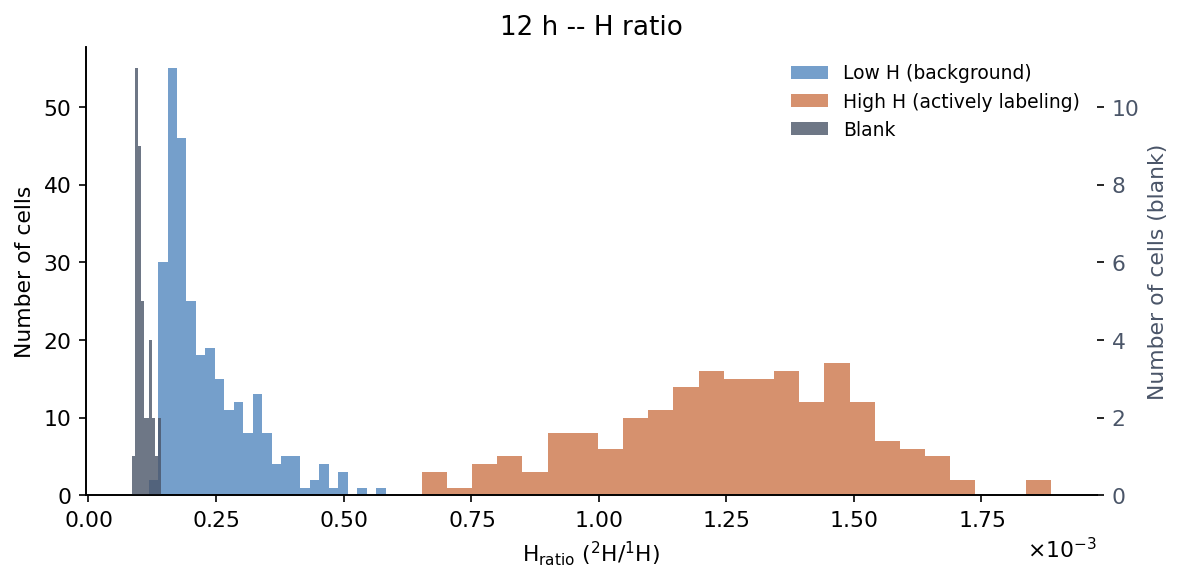

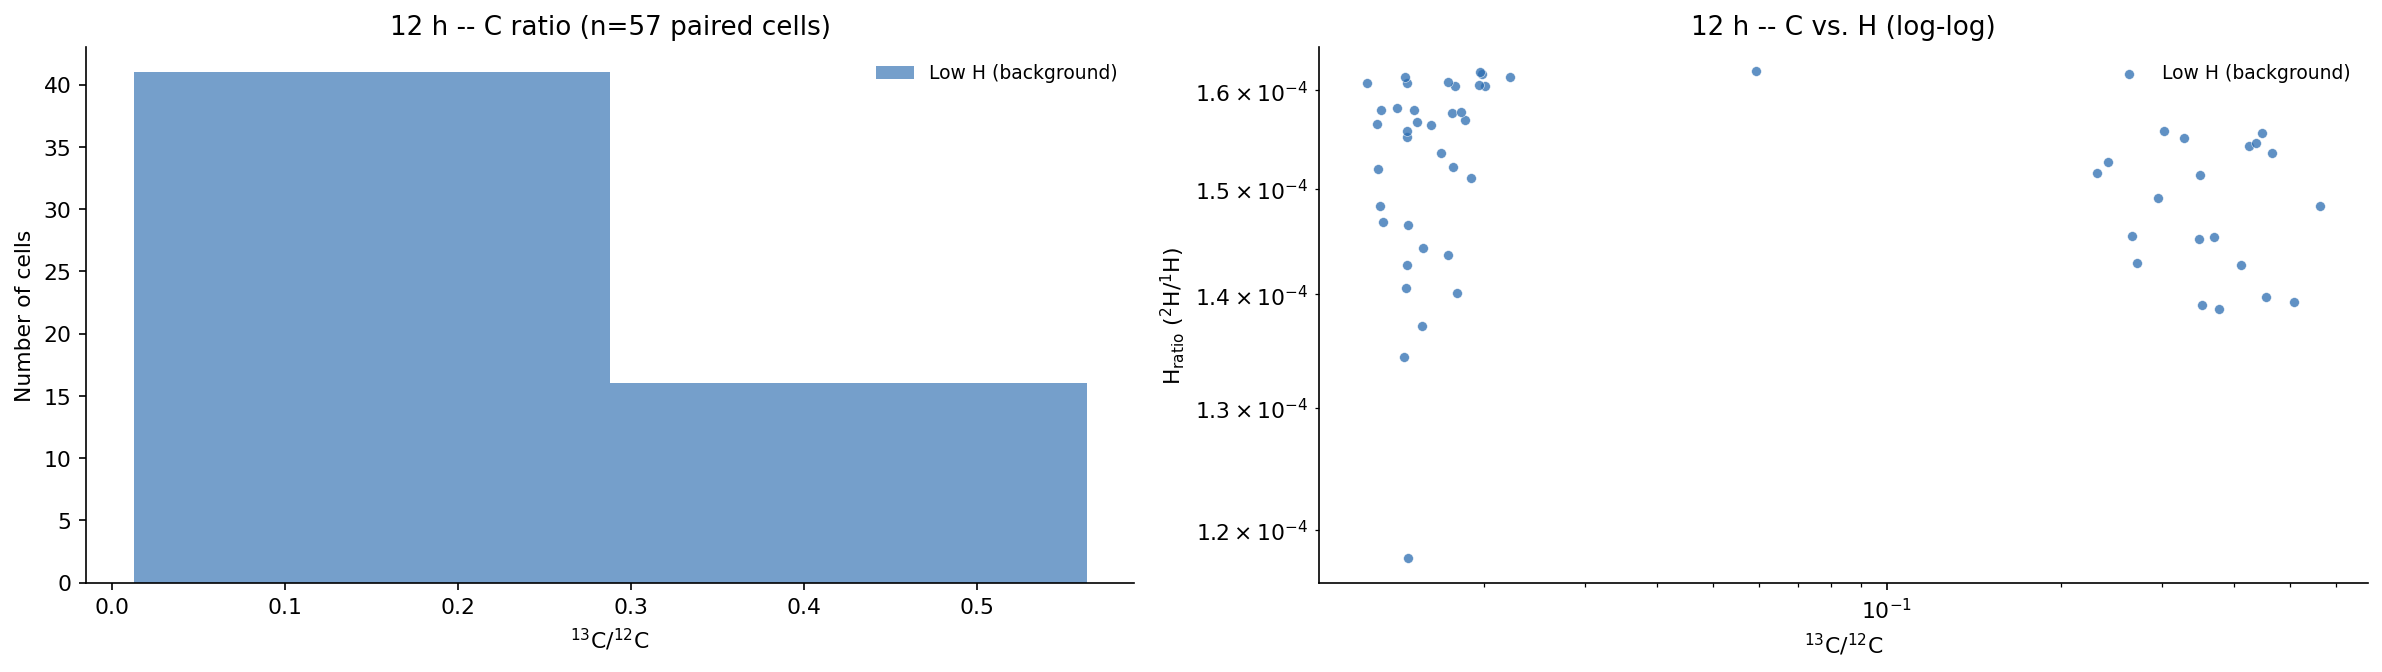

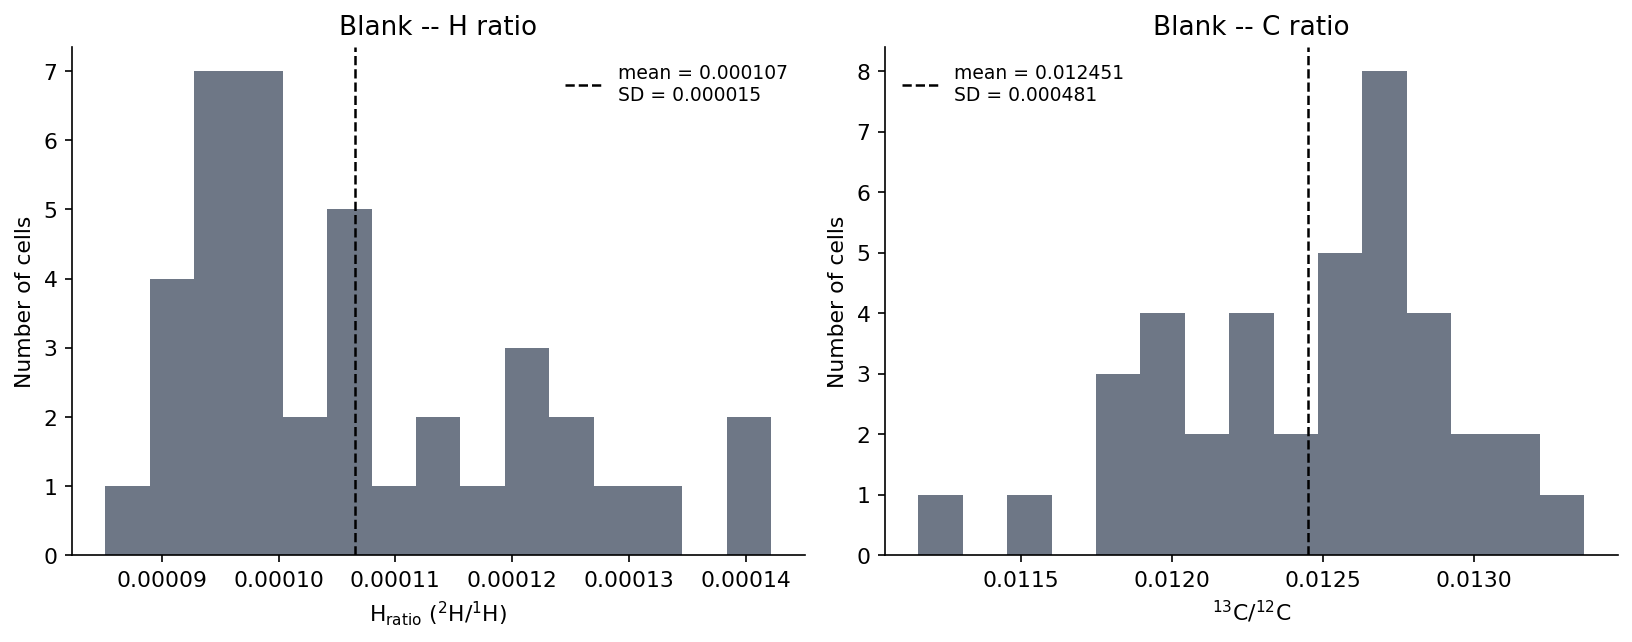

In [36]:
"""
H-isotope (2H/1H, "H_ratio") single-cell analysis.

  - 12h_H.ods : bimodal GMM clustering (log-space, same convention as the
    C_ratio/N_ratio clustering used elsewhere in the paper) on H_ratio
    jointly with 13C/12C, plus the histogram/scatter figure.
  - blank_H.ods : distribution + summary statistics ONLY, no clustering.
"""

import numpy as np
import pandas as pd
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# ----------------------------------------------------------------------
# Style (kept consistent with the rest of the paper's figures)
# ----------------------------------------------------------------------
CLUSTER_COLORS = {0: "#2b6cb0", 1: "#c05621"}  # 0 = low/background, 1 = high/labeling
CLUSTER_LABELS = {0: "Low H (background)", 1: "High H (actively labeling)"}
BLANK_COLOR = "#4a5568"

H12_PATH = "experiments/new_data/replicates/12h_H.ods"
BLANK_PATH = "experiments/new_data/replicates/blank_H.ods"


# ----------------------------------------------------------------------
# Load + normalize column naming (the 12h file calls the carbon ratio
# column "13C/12C", the blank file calls it "C_ratio" -- unify to
# "C_ratio" for both so the same code can handle either).
# ----------------------------------------------------------------------
def load(path):
    df = pd.read_excel(path, engine="odf")
    if "13C/12C" in df.columns:
        df = df.rename(columns={"13C/12C": "C_ratio"})
    return df


h12 = load(H12_PATH)
blank = load(BLANK_PATH)


# ----------------------------------------------------------------------
# GMM clustering in log-space (same pattern as cluster_log_ratios used
# for C_ratio/N_ratio elsewhere: log-transform -> standardize -> fit a
# 2-component GMM -> relabel clusters by ascending mean so cluster 0 is
# always the low/background population and cluster 1 the high one).
#
# Note: only 57 of the 487 cells in 12h_H.ods have a paired 13C/12C
# measurement (the carbon channel is NaN for the rest -- these pixels
# were only covered by the hydrogen imaging pass). The clustering is
# therefore done on H_ratio alone, using all 487 cells; C_ratio is used
# only where available, to color-check the H-based clusters against the
# independent carbon-labeling signal in the scatter panel below.
# ----------------------------------------------------------------------
def cluster_log_ratio(values, random_state=0):
    log_vals = np.log10(values.to_numpy()).reshape(-1, 1)
    scaler = StandardScaler()
    z = scaler.fit_transform(log_vals)

    gmm = GaussianMixture(n_components=2, random_state=random_state, n_init=10)
    raw_labels = gmm.fit_predict(z)

    means_per_raw = [log_vals[raw_labels == k, 0].mean() for k in range(2)]
    remap = {old: new for new, old in enumerate(np.argsort(means_per_raw))}
    labels = np.array([remap[l] for l in raw_labels])
    return labels, gmm


h12["cluster"] = cluster_log_ratio(h12["H_ratio"])[0]

n_paired = h12["C_ratio"].notna().sum()
print(f"=== 12h_H.ods : {n_paired}/{len(h12)} cells have a paired 13C/12C value ===")
print("=== 12h_H.ods : cluster sizes and stats ===")
for k in (0, 1):
    sub = h12[h12["cluster"] == k]
    sub_c = sub["C_ratio"].dropna()
    c_str = (
        f"{sub_c.mean():.6f} +/- {sub_c.std(ddof=1):.6f} (n={len(sub_c)})"
        if len(sub_c) > 1 else "n/a"
    )
    print(
        f"cluster {k} ({CLUSTER_LABELS[k]}): n={len(sub)}, "
        f"H_ratio = {sub['H_ratio'].mean():.6f} +/- {sub['H_ratio'].std(ddof=1):.6f}, "
        f"C_ratio = {c_str}"
    )

# ----------------------------------------------------------------------
# blank_H.ods : distribution + summary stats only (no clustering)
# ----------------------------------------------------------------------
blank_H_mean, blank_H_std = blank["H_ratio"].mean(), blank["H_ratio"].std(ddof=1)
blank_C_mean, blank_C_std = blank["C_ratio"].mean(), blank["C_ratio"].std(ddof=1)

print("\n=== blank_H.ods : distribution stats (no clustering) ===")
print(f"n = {len(blank)}")
print(f"H_ratio = {blank_H_mean:.6f} +/- {blank_H_std:.6f}")
print(f"C_ratio = {blank_C_mean:.6f} +/- {blank_C_std:.6f}")

# ----------------------------------------------------------------------
# FIGURE 1 -- 12h_H.ods : histograms by cluster + log-log scatter
#   panel 1: H_ratio histogram, colored by cluster
#   panel 2: C_ratio histogram, colored by cluster
#   panel 3: log-log scatter of C_ratio vs H_ratio, colored by cluster
# (single-timepoint version of the 3x3 T4/T12/T24 figure used for C/N)
# ----------------------------------------------------------------------
fig, axes = plt.subplots(1, 1, figsize=(8, 4))

ax = axes
for k in (0, 1):
    vals = h12.loc[h12["cluster"] == k, "H_ratio"]
    ax.hist(vals, bins=25, alpha=0.65, color=CLUSTER_COLORS[k], label=CLUSTER_LABELS[k])
ax.set_xlabel(r"H$_{\mathrm{ratio}}$ ($^2$H/$^1$H)")
ax.set_ylabel("Number of cells")
ax.set_title("12 h -- H ratio")
ax.ticklabel_format(axis="x", style="sci", scilimits=(0, 0), useMathText=True)

ax2 = ax.twinx()
ax2.hist(blank["H_ratio"], bins=10, color=BLANK_COLOR, alpha=0.8, label="Blank")
ax2.set_ylabel("Number of cells (blank)", color=BLANK_COLOR)
ax2.tick_params(axis="y", labelcolor=BLANK_COLOR)

# combine legends from both axes into one
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, frameon=False, fontsize=9)

plt.tight_layout()
plt.savefig("h_isotope_12h_clusters.png", dpi=200, bbox_inches="tight")
plt.show()



fig, axes = plt.subplots(1, 2, figsize=(16, 4.6))
ax = axes[0]
for k in (0, 1):
    vals = h12.loc[h12["cluster"] == k, "C_ratio"].dropna()
    if len(vals):
        ax.hist(vals, bins=2, alpha=0.65, color=CLUSTER_COLORS[k], label=CLUSTER_LABELS[k])
ax.set_xlabel(r"$^{13}$C/$^{12}$C")
ax.set_ylabel("Number of cells")
ax.set_title(f"12 h -- C ratio (n={n_paired} paired cells)")
ax.legend(frameon=False, fontsize=9)

ax = axes[1]
paired = h12.dropna(subset=["C_ratio"])
for k in (0, 1):
    sub = paired[paired["cluster"] == k]
    if len(sub) == 0:
        continue
    ax.scatter(
        sub["C_ratio"], sub["H_ratio"], s=22, alpha=0.75,
        color=CLUSTER_COLORS[k], edgecolor="white", linewidth=0.3,
        label=CLUSTER_LABELS[k],
    )
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel(r"$^{13}$C/$^{12}$C")
ax.set_ylabel(r"H$_{\mathrm{ratio}}$ ($^2$H/$^1$H)")
ax.set_title("12 h -- C vs. H (log-log)")
ax.legend(frameon=False, fontsize=9)

plt.tight_layout()
#plt.savefig("h_isotope_12h_clusters.png", dpi=200, bbox_inches="tight")
plt.show()

# ----------------------------------------------------------------------
# FIGURE 2 -- blank_H.ods : distributions only, no clustering
# ----------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))

ax = axes[0]
ax.hist(blank["H_ratio"], bins=15, color=BLANK_COLOR, alpha=0.8)
ax.axvline(blank_H_mean, color="black", lw=1.2, ls="--",
           label=f"mean = {blank_H_mean:.6f}\nSD = {blank_H_std:.6f}")
ax.set_xlabel(r"H$_{\mathrm{ratio}}$ ($^2$H/$^1$H)")
ax.set_ylabel("Number of cells")
ax.set_title("Blank -- H ratio")
ax.legend(frameon=False, fontsize=9)

ax = axes[1]
ax.hist(blank["C_ratio"], bins=15, color=BLANK_COLOR, alpha=0.8)
ax.axvline(blank_C_mean, color="black", lw=1.2, ls="--",
           label=f"mean = {blank_C_mean:.6f}\nSD = {blank_C_std:.6f}")
ax.set_xlabel(r"$^{13}$C/$^{12}$C")
ax.set_ylabel("Number of cells")
ax.set_title("Blank -- C ratio")
ax.legend(frameon=False, fontsize=9)

plt.tight_layout()
plt.savefig("h_isotope_blank_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

In [12]:
blank

,H_ratio,2H,1H,pixsize,Xi,Yi,13C,12C,C_ratio
0,0.000085,75.41423,885578.7,2774,45.63,457.01,62611.49,5058453,0.012378
1,0.000091,116.08810,1270318.0,2772,74.84,125.33,64017.86,4862376,0.013166
2,0.000102,111.42960,1089800.0,2719,92.98,343.06,64244.57,5048081,0.012727
3,0.000098,138.92140,1412008.0,2570,100.09,266.94,58876.93,4593336,0.012818
4,0.000107,192.11050,1794550.0,3007,157.09,279.78,103130.90,7996030,0.012898
5,0.000094,74.22870,792606.7,2368,178.06,482.16,57983.96,4620271,0.012550
6,0.000097,196.44740,2021713.0,3244,200.69,223.85,108311.20,8359913,0.012956
7,0.000094,151.75420,1605956.0,2649,202.45,152.16,69071.56,5257249,0.013138
8,0.000098,107.01980,1096988.0,2441,232.04,277.40,74046.93,5751217,0.012875
9,0.000104,108.26870,1038309.0,2256,246.25,348.02,67393.00,5279837,0.012764


## 2. Peak fits: mean AND std per peak per timepoint

At $t=0$h (blank), there's only one population — its overall mean/std stand in for
both "peak slots" (no split yet).


In [17]:
def fit_bimodal_2d(data, seed=42):
    scaler = StandardScaler()
    X = scaler.fit_transform(data[["logC", "logN"]])
    model = GaussianMixture(
        n_components=2, covariance_type="full",
        random_state=seed, n_init=10,
    )
    raw_labels = model.fit_predict(X)
    score = X.sum(axis=1)
    order = pd.Series(score, index=data.index).groupby(raw_labels).mean().sort_values().index
    relabel = {old: new for new, old in enumerate(order)}
    labels = np.array([relabel[l] for l in raw_labels])  # 0 = low, 1 = high, now actually returned
    data["cluster"] = labels
    return labels


log_blank_N = np.log(blank.N_ratio)
log_blank_C = np.log(blank.C_ratio)import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

df = pooled['12h']
logC = np.log(df["C_ratio"])
logN = np.log(df["N_ratio"])
data = pd.DataFrame({"logC": logC, "logN": logN}).replace([np.inf, -np.inf], np.nan).dropna()

# z-score so logC and logN weigh equally in the distance
scaler = StandardScaler()
X = scaler.fit_transform(data[["logC", "logN"]])

km = KMeans(n_clusters=2, n_init=10, random_state=42)
labels = km.fit_predict(X)

# relabel so 0 = low group, 1 = high group (k-means labels are arbitrary)
order = np.argsort(km.cluster_centers_.sum(axis=1))
relabel = {old: new for new, old in enumerate(order)}
data["cluster"] = [relabel[l] for l in labels]
centers = scaler.inverse_transform(km.cluster_centers_[order])  # back to log units

colors = ["#2a78d6", "#eb6834"]
fig, ax = plt.subplots(figsize=(5, 4.5))
for k in (0, 1):
    sub = data[data["cluster"] == k]
    ax.scatter(sub["logC"], sub["logN"], s=14, alpha=0.7, color=colors[k],
               edgecolor="white", linewidth=0.3, label=f"Cluster {k} (n={len(sub)})")
ax.scatter(centers[:, 0], centers[:, 1], marker="X", s=120, color="black", label="Centroids")
ax.set_xlabel("log(¹³C/¹²C)")
ax.set_ylabel("log(¹⁵N/¹⁴N)")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

print(data.groupby("cluster")[["logC", "logN"]].agg(["mean", "std", "count"]))

peak_stats = {"0h": {
    "N": (np.array([blank.N_ratio.mean()] * 2), np.array([blank.N_ratio.std(ddof=1)] * 2)),
    "C": (np.array([blank.C_ratio.mean()] * 2), np.array([blank.C_ratio.std(ddof=1)] * 2)),
}}
peak_stats_log = {"0h": {
    "N": (np.array([log_blank_N.mean()] * 2), np.array([log_blank_N.std(ddof=1)] * 2)),
    "C": (np.array([log_blank_C.mean()] * 2), np.array([log_blank_C.std(ddof=1)] * 2)),
}}

cluster_labels = {}
for tp in timepoints:
    df = pooled[tp]
    logC = np.log(df["C_ratio"])
    logN = np.log(df["N_ratio"])
    data = pd.DataFrame({"logC": logC, "logN": logN})
    # if C_ratio/N_ratio can be 0 or negative, guard here before fitting:
    # data = data.replace([np.inf, -np.inf], np.nan).dropna()
    # df = df.loc[data.index]

    labels = fit_bimodal_2d(data)   # now genuinely 0=low, 1=high
    df['labels'] = labels
    data['labels'] = labels

    peak_stats[tp] = {
        "N": (
            np.array([df.loc[df["labels"] == 0, "N_ratio"].mean(), df.loc[df["labels"] == 1, "N_ratio"].mean()]),
            np.array([df.loc[df["labels"] == 0, "N_ratio"].std(ddof=1), df.loc[df["labels"] == 1, "N_ratio"].std(ddof=1)]),
        ),
        "C": (
            np.array([df.loc[df["labels"] == 0, "C_ratio"].mean(), df.loc[df["labels"] == 1, "C_ratio"].mean()]),
            np.array([df.loc[df["labels"] == 0, "C_ratio"].std(ddof=1), df.loc[df["labels"] == 1, "C_ratio"].std(ddof=1)]),
        ),
    }
    peak_stats_log[tp] = {
        "N": (
            np.array([data.loc[data["labels"] == 0, "logN"].mean(), data.loc[data["labels"] == 1, "logN"].mean()]),
            np.array([data.loc[data["labels"] == 0, "logN"].std(ddof=1), data.loc[data["labels"] == 1, "logN"].std(ddof=1)]),
        ),
        "C": (
            np.array([data.loc[data["labels"] == 0, "logC"].mean(), data.loc[data["labels"] == 1, "logC"].mean()]),
            np.array([data.loc[data["labels"] == 0, "logC"].std(ddof=1), data.loc[data["labels"] == 1, "logC"].std(ddof=1)]),
        ),
    }

    cluster_labels[tp] = labels

In [18]:
peak_stats

{'0h': {'N': (array([0.00393306, 0.00393306]),
   array([9.73965081e-05, 9.73965081e-05])),
  'C': (array([0.01040787, 0.01040787]), array([0.00022482, 0.00022482]))},
 '4h': {'N': (array([0.00910806, 0.04533426]),
   array([0.00793007, 0.02339912])),
  'C': (array([0.01315825, 0.03079956]), array([0.00117142, 0.00556334]))},
 '12h': {'N': (array([0.01718322, 0.10875052]),
   array([0.01962092, 0.04097905])),
  'C': (array([0.01393642, 0.04897227]), array([0.00300626, 0.01051524]))},
 '24h': {'N': (array([0.01262805, 0.14198211]),
   array([0.01747063, 0.08325778])),
  'C': (array([0.01176726, 0.05159253]), array([0.00127149, 0.02012616]))}}

## 3. Standardize, project, and compute the specific incorporation rate

$$k = \frac{x-\mu_{t,j}}{\sigma_{t,j}}, \qquad
x_{t-\Delta t} = \mu_{t-\Delta t,\,j} + k\,\sigma_{t-\Delta t,\,j}$$

$$r_{\mathrm{cell}} = \frac{1}{T}\log\frac{x_t}{x_{t-\Delta t}}$$

No asymptotic ceiling ($x_1$) is used here — this is a plain specific (log fold-change)
rate. This matters: an earlier version of this analysis normalized by the gap to a
per-isotope ceiling $x_1$, and because $x_1^{(^{13}C)}$ is roughly 8x smaller than
$x_1^{(^{15}N)}$, that made carbon's *fractional* progress look faster than nitrogen's
even though nitrogen moves much further in absolute terms. This formula has no such
scale dependence.


In [19]:
def rate_formula(logx_end, logx_start, Tdur):
    return (logx_end - logx_start) / Tdur

segments = [("0h", "4h"), ("4h", "12h"), ("12h", "24h")]
segment_results = {}

for (t_start, t_end) in segments:
    Tdur = T_clock[t_end] - T_clock[t_start]

    df_end = pooled[t_end].reset_index(drop=True)
    cl_end = np.asarray(cluster_labels[t_end])
    assert len(df_end) == len(cl_end)

    logC_end = np.log(df_end["C_ratio"].to_numpy())
    logN_end = np.log(df_end["N_ratio"].to_numpy())

    meansC_end, stdsC_end = peak_stats_log[t_end]["C"]
    meansN_end, stdsN_end = peak_stats_log[t_end]["N"]
    meansC_start, stdsC_start = peak_stats_log[t_start]["C"]
    meansN_start, stdsN_start = peak_stats_log[t_start]["N"]

    rates_C = np.empty(len(df_end))
    rates_N = np.empty(len(df_end))

    for cluster in (0, 1):
        mask = cl_end == cluster
        kC = (logC_end[mask] - meansC_end[cluster]) / stdsC_end[cluster]
        kN = (logN_end[mask] - meansN_end[cluster]) / stdsN_end[cluster]

        logC_start_proj = meansC_start[cluster] + kC * stdsC_start[cluster]
        logN_start_proj = meansN_start[cluster] + kN * stdsN_start[cluster]

        rates_C[mask] = rate_formula(logC_end[mask], logC_start_proj, Tdur)
        rates_N[mask] = rate_formula(logN_end[mask], logN_start_proj, Tdur)

    df_end["C_rates"] = rates_C
    df_end["N_rates"] = rates_N
    df_end["cluster"] = cl_end
    segment_results[(t_start, t_end)] = df_end

In [25]:
df_end = segment_results[('4h', '12h')]
df_end_cluster = df_end['cluster']
df_end_cluster.to_csv('results_new/clusters_4to12h_N_NEW.dat', index=None)

In [13]:
df_end = segment_results[('4h', '12h')]
df_end_N = df_end['N_rates']
df_end_N.to_csv('peak_movement_rates_4to12h_N_NEW.dat', index=None)
df_end_C = df_end['C_rates']
df_end_C.to_csv('peak_movement_rates_4to12h_C_NEW.dat', index=None)

## 4. Write output files

Two files per segment (both replicates pooled), N before C. Columns: `[rate,
peak_assignment]` (0=low, 1=high).


In [12]:
seg_names = {("0h","4h"): "0to4h", ("4h","12h"): "4to12h", ("12h","24h"): "12to24h"}

for seg in segments:
    sname = seg_names[seg]
    for iso in ["N_rates", "C_rates"]:
        r = segment_results[seg][iso]
        fname = f"peak_movement_rates_{sname}_{iso}.dat"
        with open(fname, "w") as f:
            for ri, ci in zip(r, cl):
                f.write(f"{ri}\t{ci}\n")
        print(f"wrote {fname}  (rows={len(r)}, excluded={ex})")


NameError: name 'cl' is not defined

In [18]:
peak_stats

{'0h': {'N': (array([0.00393306, 0.00393306]),
   array([9.73965081e-05, 9.73965081e-05])),
  'C': (array([0.01040787, 0.01040787]), array([0.00022482, 0.00022482]))},
 '4h': {'N': (array([0.00801677, 0.04520383]),
   array([0.00758123, 0.02347864])),
  'C': (array([0.01290945, 0.03075437]), array([0.00124923, 0.00561315]))},
 '12h': {'N': (array([0.01718322, 0.10875052]),
   array([0.01962092, 0.04097905])),
  'C': (array([0.01393642, 0.04897227]), array([0.00300626, 0.01051524]))},
 '24h': {'N': (array([0.01240284, 0.14198211]),
   array([0.0171856 , 0.08325778])),
  'C': (array([0.01169955, 0.05159253]), array([0.00129465, 0.02012616]))}}

## 5. Peak trajectories (no ceiling reference line)

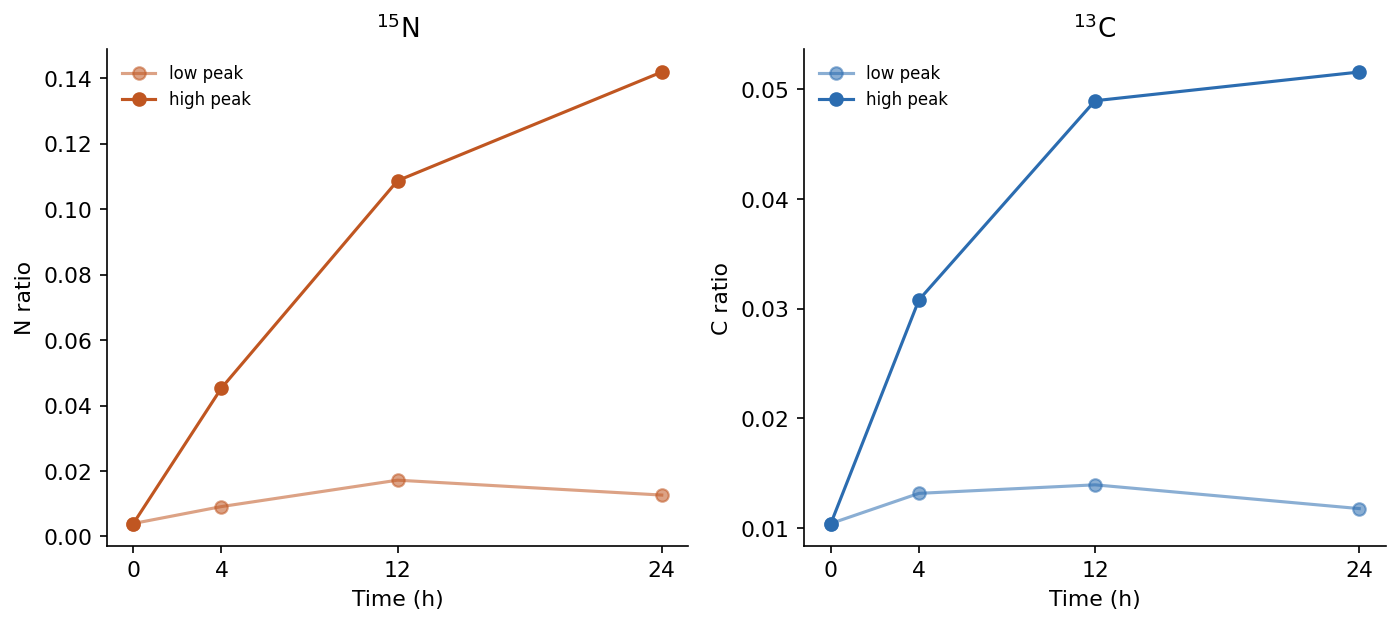

Saved figures/peak_trajectories.png


In [11]:
timeline = ["0h"] + timepoints
t_vals = [T_clock[t] for t in timeline]
colors = {"N": "#c05621", "C": "#2b6cb0"}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
for ax, iso in zip(axes, ["N", "C"]):
    low_traj = [peak_stats["0h"][iso][0][0]] + [peak_stats[tp][iso][0][0] for tp in timepoints]
    high_traj = [peak_stats["0h"][iso][0][0]] + [peak_stats[tp][iso][0][1] for tp in timepoints]
    ax.plot(t_vals, low_traj, "o-", color=colors[iso], alpha=0.55, label="low peak")
    ax.plot(t_vals, high_traj, "o-", color=colors[iso], alpha=1.0, label="high peak")
    ax.set_xlabel("Time (h)")
    ax.set_ylabel(f"{iso} ratio")
    ax.set_title(r"$^{15}$N" if iso == "N" else r"$^{13}$C")
    ax.set_xticks(t_vals)
    ax.legend(frameon=False, fontsize=8)
#plt.tight_layout()
plt.savefig("peak_trajectories.png", dpi=200, bbox_inches="tight")
plt.show()
print("Saved figures/peak_trajectories.png")


## 6. Segment rate distributions, with individual cells overlaid

In [23]:
segment_results

{('0h',
  '4h'):       C_ratio   N_ratio        13C        12C       12C15N   12C14N  pixsize  \
 0    0.033184  0.035510  34376.400  1035947.0    82731.920  2329823     1563   
 1    0.029190  0.016547  23879.880   818083.6    30984.370  1872526     1425   
 2    0.011202  0.004760  10060.540   898112.3     8504.784  1786600     1274   
 3    0.011473  0.004779   7476.176   651638.5     4794.254  1003198      783   
 4    0.012503  0.006951  12412.940   992824.2    13275.150  1909785     1225   
 ..        ...       ...        ...        ...          ...      ...      ...   
 586  0.021592  0.048120  34226.560  1585178.0  1585178.000  6640109     1182   
 587  0.032494  0.058821  60783.170  1870593.0  1870593.000  6862081     1409   
 588  0.032377  0.100090  47269.300  1459951.0  1459951.000  5257849     1116   
 589  0.037282  0.085221  58214.740  1561482.0  1561482.000  5735435     1160   
 590  0.027498  0.064402  39810.480  1447739.0  1447739.000  5035429      863   
 
          

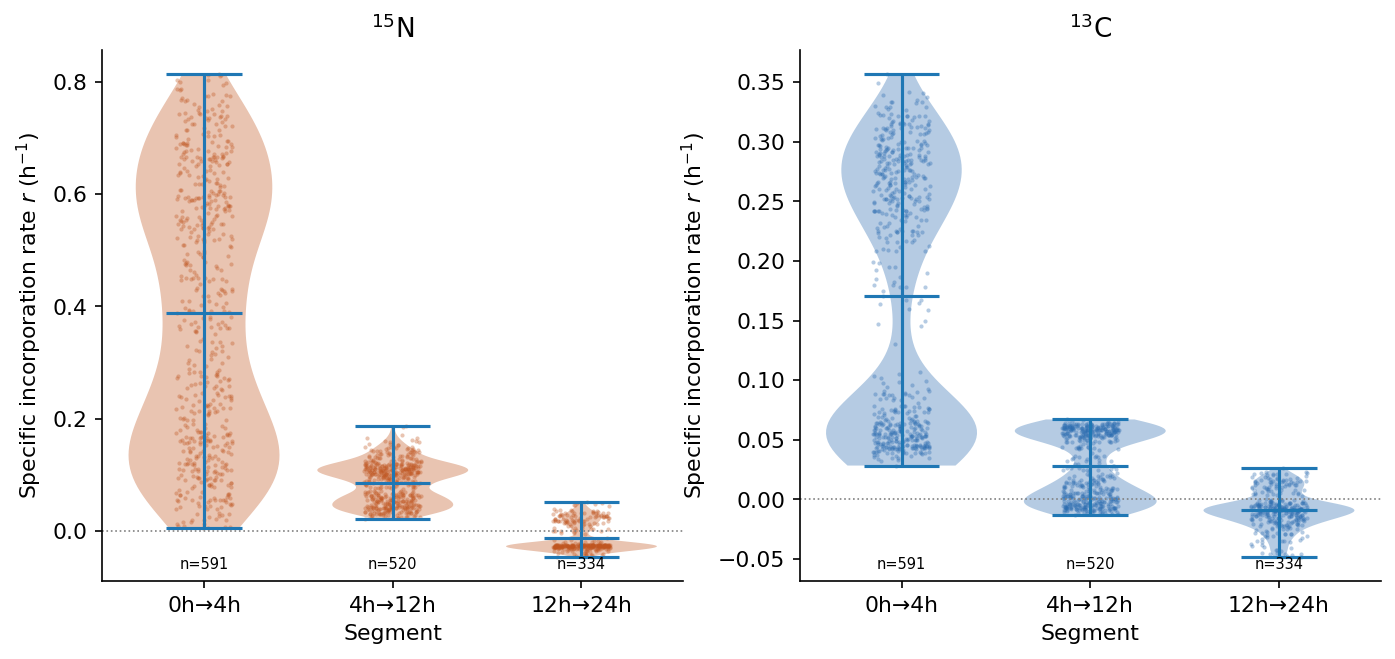

Saved figures/segment_rate_violin.png


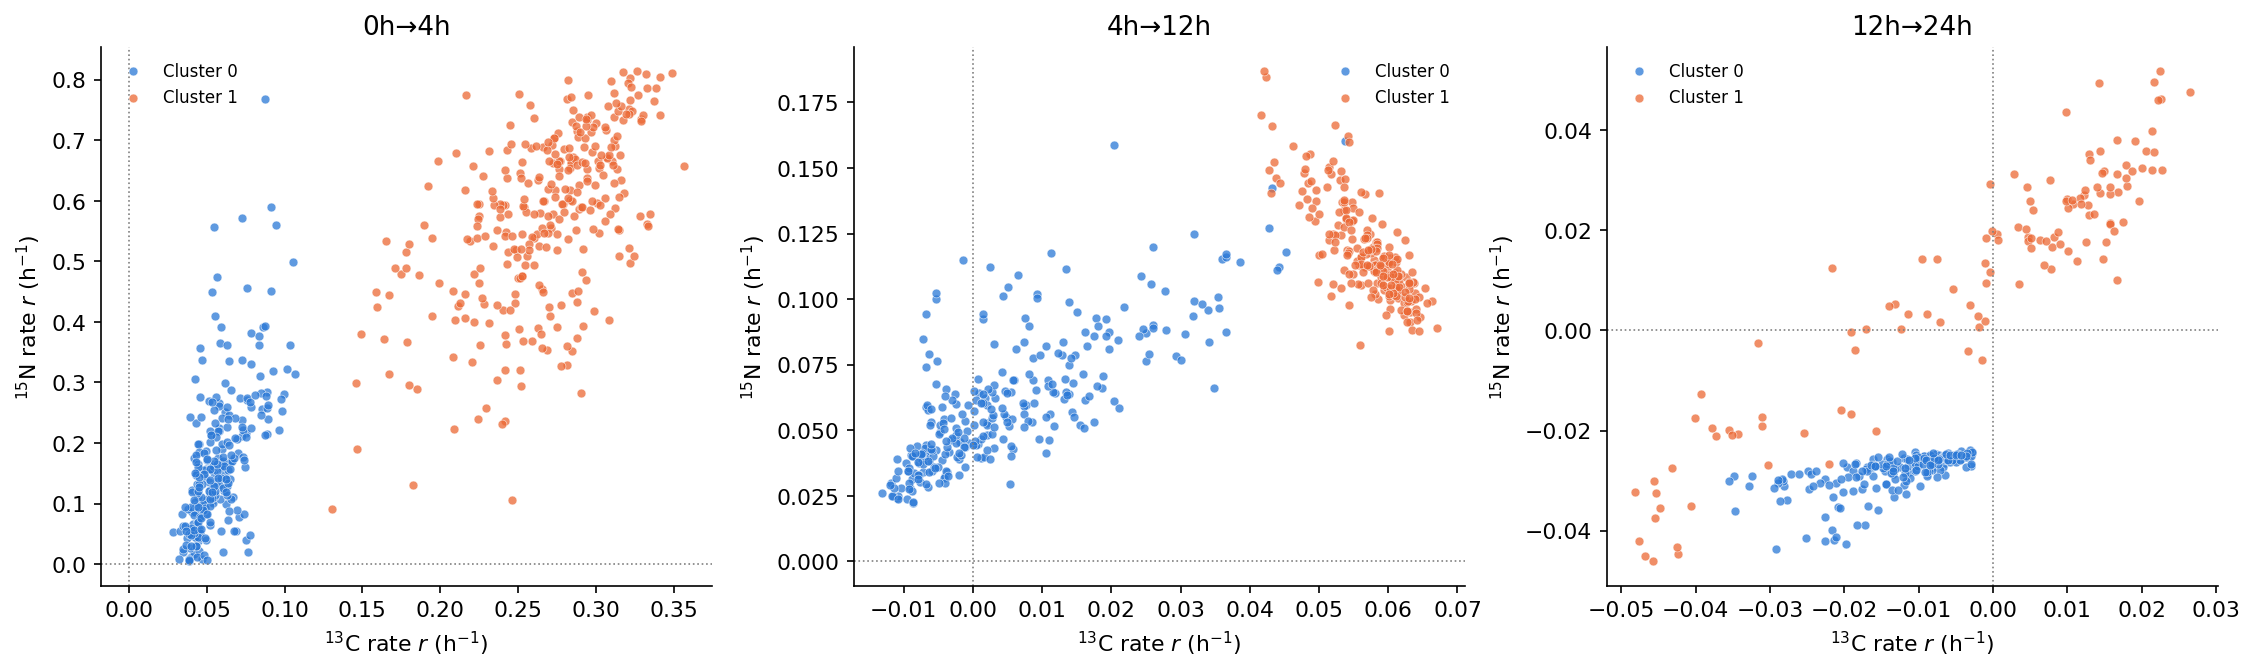

Saved figures/segment_rate_scatter.png


In [14]:
seg_labels = ["0h\u21924h", "4h\u219212h", "12h\u219224h"]
colors = {"N_rates": "#c05621", "C_rates": "#2b6cb0"}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, iso in zip(axes, ["N_rates", "C_rates"]):
    vals = [segment_results[seg][iso] for seg in segments]
    parts = ax.violinplot(vals, showmeans=True, showextrema=True, widths=0.8, )
    for pc in parts["bodies"]:
        pc.set_facecolor(colors[iso])
        pc.set_alpha(0.35)
    for i, v in enumerate(vals):
        jitter = rng.uniform(-0.15, 0.15, size=len(v))
        ax.scatter(np.full(len(v), i + 1) + jitter, v, s=4, color=colors[iso],
                   alpha=0.35, linewidths=0)
    ax.set_xticks(range(1, len(segments) + 1))
    ax.set_xticklabels(seg_labels)
    ax.set_xlabel("Segment")
    ax.set_ylabel(r"Specific incorporation rate $r$ (h$^{-1}$)")
    ax.set_title(r"$^{15}$N" if iso == "N_rates" else r"$^{13}$C")
    ax.axhline(0, color="gray", lw=0.8, ls=":")
    ymin = min(v.min() for v in vals)
    for i, v in enumerate(vals):
        ax.text(i + 1, ymin, f"n={len(v)}", ha="center", va="top", fontsize=7)
#plt.tight_layout()
plt.savefig( "segment_rate_violin.png", dpi=200, bbox_inches="tight")
plt.show()
print("Saved figures/segment_rate_violin.png")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))

for ax, seg, label in zip(axes, segments, seg_labels):
    df_end = segment_results[seg]
    for cluster in (0, 1):
        sub = df_end[df_end["cluster"] == cluster]
        ax.scatter(
            sub["C_rates"], sub["N_rates"],
            s=18, alpha=0.75,
            color=CLUSTER_COLORS[cluster],
            edgecolor="white", linewidth=0.3,
            label=f"Cluster {cluster}",
        )
    ax.axhline(0, color="gray", lw=0.8, ls=":")
    ax.axvline(0, color="gray", lw=0.8, ls=":")
    ax.set_xlabel(r"$^{13}$C rate $r$ (h$^{-1}$)")
    ax.set_ylabel(r"$^{15}$N rate $r$ (h$^{-1}$)")
    ax.set_title(label)
    ax.legend(frameon=False, fontsize=8)

plt.tight_layout()
plt.savefig("segment_rate_scatter.png", dpi=200, bbox_inches="tight")
plt.show()
print("Saved figures/segment_rate_scatter.png")

## 7. Summary table

In [15]:
rows = []
for seg, lbl in zip(segments, seg_labels):
    for iso in ["N_rates", "C_rates"]:
        r = segment_results[seg][iso]
        rows.append({
            "segment": lbl, "isotope": iso[0], "n": len(r),
            "mean": r.mean(), "median": np.median(r), "sd": r.std(ddof=1),
            "frac_negative": (r < 0).mean(),
        })
segment_summary = pd.DataFrame(rows)
segment_summary.to_csv("segment_rate_summary.csv", index=False)
segment_summary.round(5)


,segment,isotope,n,mean,median,sd,frac_negative
0,0h→4h,N,591,0.38736,0.39007,0.23996,0.00000
1,0h→4h,C,591,0.17066,0.19498,0.10941,0.00000
2,4h→12h,N,520,0.08589,0.09237,0.03634,0.00000
3,4h→12h,C,520,0.02778,0.02444,0.02784,0.24423
4,12h→24h,N,334,-0.01303,-0.02553,0.02431,0.71257
5,12h→24h,C,334,-0.00869,-0.00888,0.01531,0.77545


## 8. Nitrogen is faster than carbon, at every segment

With this formula, $^{15}$N incorporates faster than $^{13}$C at **every** segment
(0.359 vs 0.153 h$^{-1}$ at 0-4h; 0.058 vs 0.022 h$^{-1}$ at 4-12h; 0.010 vs -0.003
h$^{-1}$ at 12-24h) — consistent with the raw peak trajectories: the $^{15}$N high
peak keeps climbing steadily through 24h, while $^{13}$C's plateaus after 4h.

### Why is 12h→24h negative for carbon?

83% of $^{13}$C cells give a negative rate in this segment despite the peak *mean*
barely moving (0.04394→0.04411). This is a real, explainable consequence of applying
a linear ($\mu+k\sigma$) standardization to a right-skewed quantity whose spread is
still growing: at 24h the $^{13}$C distribution has skewness 1.49 (70% of cells sit
below the mean), so most individual $k$ are negative; combined with the high peak's
growing spread ($\sigma_{12h}=0.013\to\sigma_{24h}=0.019$), rescaling that negative
$k$ by the smaller previous-timepoint $\sigma$ pushes the projected reference above
the cell's actual value for most cells — read as a negative rate. This is consistent
with an essentially flat/plateaued carbon high peak in that interval, not literal
isotopic loss.


In [9]:
# quantify the skew driving this, for the diagnostic segment
for tp in ["12h", "24h"]:
    vals = pooled[tp].C_ratio.values
    print(f"{tp} C_ratio: mean={vals.mean():.5f}  median={np.median(vals):.5f}  "
          f"skew={skew(vals):.3f}  frac_below_mean={(vals < vals.mean()).mean():.1%}")


12h C_ratio: mean=0.02685  median=0.01585  skew=0.753  frac_below_mean=61.7%
24h C_ratio: mean=0.02390  median=0.01343  skew=1.486  frac_below_mean=70.4%
